# Structure Factor Analysis with Radius Parameter

Analysis of binary polymer simulations with nanoparticle packing, including nanoparticle radius as a variable.

## Parameters
- **NP_frac**: [0.5, 0.64]
- **RAD**: [3.75, 5]
- **POT**: [10.0, 13.75, 17.5, 21.25, 25.0]
- **Nb**: [5, 10, 20]
- **rep**: [0, 1, 2]

In [1]:
# Cell 1: Imports and Simulation Parameters
import numpy as np
import matplotlib.pyplot as plt
import math
import os
import pandas as pd
import glob
import subprocess
import re
from matplotlib.ticker import MultipleLocator
import matplotlib
import seaborn as sns
from scipy.optimize import curve_fit
from multiprocessing import Pool

# Set plotting style
plt.rc('font', family='serif')

# ── Simulation parameters ─────────────────────────────────────────────────────
max_steps = 2000001   # total simulation steps
n_frames  = 34        # number of logarithmic output frames
freq      = 1000      # first output frequency
L_BOX     = 51.5     # simulation box side length  (sets dk = 2*pi/L_BOX)
min_k     = 2 * math.pi / L_BOX   # minimum accessible k / q_min reference line

import pickle
from pathlib import Path

CACHE_DIR = Path("/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/cache")
CACHE_DIR.mkdir(exist_ok=True)
FORCE_RECOMPUTE = False  # set True to ignore all caches and recompute everything

def _cache_path(prefix, phi_np, rad, POT, Nb, rep, init='standard'):
    """Return cache file path with all system parameters embedded in filename."""
    return CACHE_DIR / f"{prefix}_phi{phi_np}_rad{rad}_POT{POT}_Nb{Nb}_rep{rep}_{init}.pkl"

def _load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

def _save_pkl(obj, path):
    with open(path, 'wb') as f:
        pickle.dump(obj, f)


In [2]:
# Cell 2: Helper Functions

from scipy.signal import argrelextrema
from scipy.ndimage import label


def search_files(directory):
    """Recursively search for files within subdirectories"""
    file_list = []
    for root, dirs, files in os.walk(directory):
        for file in files:
            file_list.append(os.path.join(root, file))
    return file_list


def calculate_log_steps(max_steps, n_frames, freq):
    """Calculate logarithmically spaced timesteps"""
    steps = []
    mult_factor = (max_steps / freq) ** (1 / (n_frames))
    for i in range(n_frames):
        freq = freq * mult_factor
        steps.append(int(freq))
    return steps


def choose_n_workers(n_files):
    """Pick number of Pool workers: 4 if divisible, else 3, else 2."""
    if n_files % 4 == 0:
        return 4
    elif n_files % 3 == 0:
        return 3
    else:
        return 2


def bin_sk(k_vals, sk_vals, L_box, k_max=2.0):
    """
    Radially shell-average S(k) using bin width dk = 2*pi/L_box.

    Uses np.histogram for performance (~20x faster than pd.cut + groupby).

    Parameters
    ----------
    k_vals  : array-like   |k| values
    sk_vals : array-like   S(k) magnitudes (same length as k_vals)
    L_box   : float        simulation box side length (cubic assumed)
    k_max   : float        maximum |k| to include

    Returns
    -------
    k_centers : ndarray   shell-centre |k| values  (only non-empty bins)
    sk_mean   : ndarray   mean  S(k) per shell
    sk_std    : ndarray   std   S(k) per shell
    counts    : ndarray   number of k-points per shell
    """
    dk          = 2.0 * np.pi / (L_box)
    bin_edges   = np.arange(0.0, k_max + dk, dk)
    bin_centers = bin_edges[:-1] + dk / 2.0

    k  = np.asarray(k_vals,  dtype=np.float64)
    sk = np.asarray(sk_vals, dtype=np.float64)

    counts,  _ = np.histogram(k, bins=bin_edges)
    sk_sum,  _ = np.histogram(k, bins=bin_edges, weights=sk)
    sk2_sum, _ = np.histogram(k, bins=bin_edges, weights=sk ** 2)

    valid   = counts > 0
    sk_mean = sk_sum[valid] / counts[valid]
    sk_var  = sk2_sum[valid] / counts[valid] - sk_mean ** 2
    sk_std  = np.sqrt(np.maximum(sk_var, 0.0))

    return bin_centers[valid], sk_mean, sk_std, counts[valid]


def calculate_sk_from_binary(filepath, type_indices=None, k_max=2.0, max_steps=None, freq=None):
    """
    Calculate structure factor directly from a binary density file.
    Replicates the behavior of calc-sk-per-frame.cpp using numpy FFT.

    Parameters
    ----------
    filepath     : str        - path to the .bin density file
    type_indices : list[int]  - particle types to compute SK for (default: [1])
    k_max        : float      - maximum |k| to retain in output  (default: 2.0)

    Returns
    -------
    pd.DataFrame with columns: k, structure_factor, frame, type
    """
    PI = np.pi
    if type_indices is None:
        type_indices = [1]

    with open(filepath, 'rb') as f:
        Dim    = np.frombuffer(f.read(4),       dtype=np.int32)[0]
        Nx     = np.frombuffer(f.read(4 * Dim), dtype=np.int32).copy()
        L      = np.frombuffer(f.read(4 * Dim), dtype=np.float32).copy()
        ntypes = np.frombuffer(f.read(4),       dtype=np.int32)[0]

        M = int(np.prod(Nx))

        shape   = tuple(Nx[::-1])
        idx     = [np.arange(Nx[d]) for d in range(Dim)]
        grids   = np.meshgrid(*idx[::-1], indexing='ij')
        k_sq    = np.zeros(shape, dtype=np.float64)
        for d in range(Dim):
            nd  = grids[Dim - 1 - d]
            k_d = np.where(nd < Nx[d] / 2.0,
                           2 * PI * nd            / L[d],
                           2 * PI * (nd - Nx[d]) / L[d])
            k_sq += k_d ** 2
        k_mag  = np.sqrt(k_sq).ravel().astype(np.float32)

        k_mask = (k_mag > 0) & (k_mag <= k_max)
        k_out  = k_mag[k_mask]

        bytes_per_frame = 4 * M * ntypes

        # Determine the actual number of frames in this file, then seek back.
        header_end = f.tell()
        f.seek(0, 2)
        n_file_frames = (f.tell() - header_end) // bytes_per_frame
        f.seek(header_end)

        # Per-file logarithmic step schedule (correct even when n_file_frames
        # differs from the notebook's n_frames parameter).
        file_steps = (calculate_log_steps(max_steps, n_file_frames, freq)
                      if (max_steps is not None and freq is not None and n_file_frames > 0)
                      else None)

        rows      = []
        frame_idx = 0

        while True:
            raw = f.read(bytes_per_frame)
            if len(raw) < bytes_per_frame:
                break

            all_rho = np.frombuffer(raw, dtype=np.float32)

            for t in type_indices:
                if t < 0 or t >= ntypes:
                    continue
                rho_t   = all_rho[t * M:(t + 1) * M].reshape(shape)
                sk_flat = np.abs(np.fft.fftn(rho_t) / M).ravel().astype(np.float32)

                row = {
                    'k':                k_out,
                    'structure_factor': sk_flat[k_mask],
                    'frame':            np.int16(frame_idx),
                    'type':             np.int8(t),
                }
                if file_steps is not None:
                    row['step'] = np.int32(file_steps[frame_idx])
                rows.append(pd.DataFrame(row))

            frame_idx += 1

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()


def read_positions_bin(filepath, verbose=False):
    """
    Read a MATILDA.FT positions.bin file.

    Returns: ns, Dim, L, tp, molID, frames
    """
    with open(filepath, 'rb') as f:
        ns    = np.frombuffer(f.read(4),    dtype=np.int32)[0]
        Dim   = np.frombuffer(f.read(4),    dtype=np.int32)[0]
        L_all = np.frombuffer(f.read(12),   dtype=np.float32)
        tp    = np.frombuffer(f.read(4*ns), dtype=np.int32).copy()
        molID = np.frombuffer(f.read(4*ns), dtype=np.int32).copy()

        frame_bytes = 4 * ns * Dim
        raw_frames  = []
        while True:
            raw = f.read(frame_bytes)
            if len(raw) < frame_bytes:
                break
            raw_frames.append(
                np.frombuffer(raw, dtype=np.float32).reshape(ns, Dim)
            )

    frames = np.array(raw_frames)
    L      = L_all[:Dim].copy()

    if verbose:
        print(f"  ns={ns}, Dim={Dim}, L={L}, ntypes={len(np.unique(tp))}, nframes={len(frames)}")
    return ns, Dim, L, tp, molID, frames


def compute_radial_density_profile(frame, L, tp, Nx, np_type=2, poly_type=0,
                                    r_max=None):
    """
    Compute radial density profile g(r) of poly_type particles around np_type
    particles for a single frame.

    g(r) is normalized so that g(r) -> 1 at large r (bulk density).
    Bin width is set to dr = L_min / Nx_min (grid spacing).
    """
    Dim = frame.shape[1]

    L_min = float(np.min(L))
    if r_max is None:
        r_max = L_min / 2.0

    dr_bin  = L_min / float(np.min(Nx))
    n_bins  = int(np.ceil(r_max / dr_bin))
    r_edges = np.linspace(0.0, r_max, n_bins + 1)
    r_mid   = 0.5 * (r_edges[1:] + r_edges[:-1])
    counts  = np.zeros(n_bins, dtype=np.float64)

    mask_np   = (tp == np_type)
    mask_poly = (tp == poly_type)
    n_NP      = int(np.sum(mask_np))
    n_poly    = int(np.sum(mask_poly))
    V         = float(np.prod(L))

    if n_NP == 0 or n_poly == 0:
        return r_mid, np.zeros(n_bins)

    rho_bulk = n_poly / V

    np_pos   = frame[mask_np].astype(np.float64)
    poly_pos = frame[mask_poly].astype(np.float64)
    for i in range(n_NP):
        dr = poly_pos - np_pos[i]
        for d in range(Dim):
            dr[:, d] -= L[d] * np.round(dr[:, d] / L[d])
        r = np.linalg.norm(dr, axis=1)
        hist, _ = np.histogram(r, bins=r_edges)
        counts += hist

    shell_vols = (4.0 / 3.0) * np.pi * (r_edges[1:]**3 - r_edges[:-1]**3)
    gr = counts / (n_NP * rho_bulk * shell_vols)

    return r_mid, gr


def find_first_minimum(r_mid, gr, r_start=5.0, r_end=12.0, order=2):
    """
    Finds the first minimum by looking for the first point where the
    slope turns from negative to positive, with a cap on distance.
    """
    mask = (r_mid > r_start) & (r_mid < r_end)
    r_sub = r_mid[mask]
    g_sub = gr[mask]

    if len(g_sub) < 5:
        return r_start + 2.5

    minima = argrelextrema(g_sub, np.less, order=order)[0]

    if len(minima) == 0:
        return None

    return r_sub[minima[0]]


def coordination_number(r_mid, gr, rho_bulk, r_min):
    """
    Integrate g(r) to get coordination number up to r_min.

    N_coord = 4*pi*rho_bulk * integral_0^r_min g(r) r^2 dr
    """
    mask = r_mid <= r_min
    r = r_mid[mask]
    g = gr[mask]
    integrand = 4.0 * np.pi * rho_bulk * g * r**2
    return np.trapz(integrand, r)


def read_density_fields(filepath):
    """
    Read density binary file and return per-type 3D density arrays for the last frame.

    Returns
    -------
    Nx     : int array [Dim]
    L      : float array [Dim]
    ntypes : int
    rho    : dict {type_idx: 3D array of shape (Nx[2], Nx[1], Nx[0])}
    """
    with open(filepath, 'rb') as f:
        Dim    = np.frombuffer(f.read(4),       dtype=np.int32)[0]
        Nx     = np.frombuffer(f.read(4 * Dim), dtype=np.int32).copy()
        L      = np.frombuffer(f.read(4 * Dim), dtype=np.float32).copy()
        ntypes = np.frombuffer(f.read(4),       dtype=np.int32)[0]

        M = int(np.prod(Nx))
        frame_size = M * ntypes
        frame_bytes = 4 * frame_size

        f.seek(0, 2)
        file_size = f.tell()
        header_size = 4 + 4*Dim + 4*Dim + 4
        n_frames = (file_size - header_size) // frame_bytes
        last_frame_offset = header_size + (n_frames - 1) * frame_bytes
        f.seek(last_frame_offset)

        raw = np.frombuffer(f.read(frame_bytes), dtype=np.float32)

    shape = tuple(Nx[::-1])
    rho = {}
    for t in range(ntypes):
        rho[t] = raw[t * M : (t + 1) * M].reshape(shape).copy()

    return Nx, L, ntypes, rho


def read_density_all_frames(filepath):
    """
    Read density binary file and return per-type 3D density arrays for ALL frames.

    Returns
    -------
    Nx     : int array [Dim]
    L      : float array [Dim]
    ntypes : int
    rho_frames : list of dicts, each {type_idx: 3D array (Nz, Ny, Nx)}
    """
    with open(filepath, 'rb') as f:
        Dim    = np.frombuffer(f.read(4),       dtype=np.int32)[0]
        Nx     = np.frombuffer(f.read(4 * Dim), dtype=np.int32).copy()
        L      = np.frombuffer(f.read(4 * Dim), dtype=np.float32).copy()
        ntypes = np.frombuffer(f.read(4),       dtype=np.int32)[0]

        M = int(np.prod(Nx))
        frame_size = M * ntypes
        frame_bytes = 4 * frame_size

        data = f.read()

    n_frames = len(data) // frame_bytes
    all_raw = np.frombuffer(data, dtype=np.float32)
    shape = tuple(Nx[::-1])

    rho_frames = []
    for fr in range(n_frames):
        offset = fr * frame_size
        rho = {}
        for t in range(ntypes):
            rho[t] = all_raw[offset + t*M : offset + (t+1)*M].reshape(shape).copy()
        rho_frames.append(rho)

    return Nx, L, ntypes, rho_frames


def cluster_density_field(rho_0, rho_1, target_type=0):
    """
    Identify clusters of a target polymer type using a composition-based threshold.

    A voxel belongs to a "type t cluster" if rho_t > rho_other at that grid point.
    Uses periodic boundary conditions via padding before connected-component
    labeling, so clusters that wrap around the box are correctly merged.
    """
    from scipy.ndimage import label  # local import guards against global name shadowing
    if target_type == 0:
        binary = rho_0 > 0.5
    else:
        binary = rho_1 > 0.5

    padded = np.pad(binary, 1, mode='wrap')
    labels_padded, _ = label(padded)
    labels = labels_padded[1:-1, 1:-1, 1:-1]

    unique_labels = np.unique(labels)
    unique_labels = unique_labels[unique_labels > 0]

    if len(unique_labels) == 0:
        return 0, np.array([]), labels

    parent = {lbl: lbl for lbl in unique_labels}

    def find(x):
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x

    def union(a, b):
        ra, rb = find(a), find(b)
        if ra != rb:
            parent[ra] = rb

    shape_3d = labels.shape
    for axis in range(3):
        face_0 = np.take(labels, 0, axis=axis)
        face_1 = np.take(labels, shape_3d[axis] - 1, axis=axis)
        mask = (face_0 > 0) & (face_1 > 0)
        for l0, l1 in zip(face_0[mask], face_1[mask]):
            union(l0, l1)

    root_map = {}
    new_label = 0
    relabeled = np.zeros_like(labels)
    for lbl in unique_labels:
        r = find(lbl)
        if r not in root_map:
            new_label += 1
            root_map[r] = new_label
    for lbl in unique_labels:
        relabeled[labels == lbl] = root_map[find(lbl)]

    n_clusters = len(root_map)
    sizes = np.bincount(relabeled.ravel())[1:]
    order = np.argsort(sizes)[::-1]
    sizes = sizes[order]

    return n_clusters, sizes, relabeled

_CACHE_RE = re.compile(
    r"^[^_]+_phi([\d.]+)_rad([\d.]+)_POT([\d.]+)_Nb(\d+)_rep(\d+)_(standard|sym_reset)\.pkl$"
)

def params_from_cache(path):
    """Extract simulation parameters from a cache filename.

    Returns dict with keys: phi_np, rad, POT, Nb, rep, init
    """
    from pathlib import Path as _Path
    m = _CACHE_RE.match(_Path(path).name)
    if not m:
        raise ValueError(f"Cannot parse parameters from cache filename: {path}")
    return dict(phi_np=m.group(1), rad=m.group(2), POT=m.group(3),
                Nb=m.group(4), rep=m.group(5), init=m.group(6))


def compute_np_np_rdf(frame, L, tp, Nx, np_type=2, r_max=None):
    """
    Compute NP-NP radial distribution function g(r) for a single frame.
    Uses the same bin width as compute_radial_density_profile.
    Pairs are counted from each NP center (both i->j and j->i), so
    the normalization uses rho_NP = (n_NP - 1) / V.
    """
    Dim   = frame.shape[1]
    L_min = float(np.min(L))
    if r_max is None:
        r_max = L_min / 2.0

    dr_bin  = L_min / float(np.min(Nx))
    n_bins  = int(np.ceil(r_max / dr_bin))
    r_edges = np.linspace(0.0, r_max, n_bins + 1)
    r_mid   = 0.5 * (r_edges[1:] + r_edges[:-1])

    mask_np = (tp == np_type)
    n_NP    = int(np.sum(mask_np))
    V       = float(np.prod(L))

    if n_NP < 2:
        return r_mid, np.zeros(n_bins)

    np_pos = frame[mask_np].astype(np.float64)

    # Vectorised pairwise distances with PBC
    diff = np_pos[:, np.newaxis, :] - np_pos[np.newaxis, :, :]   # (N, N, Dim)
    for d in range(Dim):
        diff[:, :, d] -= L[d] * np.round(diff[:, :, d] / L[d])
    r_all = np.linalg.norm(diff, axis=2)                          # (N, N)

    r_flat = r_all[r_all > 0]   # exclude diagonal (self-pairs)
    hist, _ = np.histogram(r_flat, bins=r_edges)
    counts  = hist.astype(np.float64)

    rho_NP     = (n_NP - 1) / V   # effective bulk density (excludes self)
    shell_vols = (4.0 / 3.0) * np.pi * (r_edges[1:]**3 - r_edges[:-1]**3)
    gr = counts / (n_NP * rho_NP * shell_vols)
    return r_mid, gr


In [3]:
# Cell 3: Load Structure Factor Data

file_directory = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Density"
#file_directory = "/home/gabriel/Projects/Asymmetric_Equilibrated_NP_Confined_PS/Results/Density"

file_pattern = re.compile(
    r"^PS_in_NP_frac_([\d.]+)_rad_([\d.]+)_POT_(10\.0|13\.75|17\.5|21\.25|25\.0)"
    r"_Nb_(\d+)_rep_(\d+)_densities\.bin$"
)

def process_file_sk(file_path):
    filename = os.path.basename(file_path)
    m = file_pattern.match(filename)
    if not m:
        return None
    print(f"Processing: {filename}")
    df = calculate_sk_from_binary(file_path, type_indices=[0,1], k_max=2.0,
                                          max_steps=max_steps, freq=freq)
    if df.empty:
        return None
    df['phi_np'] = m.group(1)
    df['rad']    = m.group(2)
    df['POT']    = m.group(3)
    df['Nb']     = m.group(4)
    df['rep']    = m.group(5)
    df['init']   = 'standard'
    return df

# Logarithmic timesteps
steps = calculate_log_steps(max_steps, n_frames, freq)
print(f"dk = 2*pi/L = {2*math.pi/L_BOX:.4f}   min_k = {min_k:.4f}")
print(f"Timesteps: {steps}")

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
files = search_files(file_directory)
hit_results, miss_files, miss_cps = [], [], []

for fpath in files:
    fname = os.path.basename(fpath)
    m_f = file_pattern.match(fname)
    if not m_f:
        continue
    phi_np_f, rad_f, POT_f, Nb_f, rep_f = (
        m_f.group(1), m_f.group(2), m_f.group(3), m_f.group(4), m_f.group(5))
    cp = _cache_path('sk', phi_np_f, rad_f, POT_f, Nb_f, rep_f, 'standard')
    if not FORCE_RECOMPUTE and cp.exists():
        _cached = _load_pkl(cp)
        if 'step' in _cached.columns:
            hit_results.append(_cached)
        else:  # old cache missing step column — recompute
            miss_files.append(fpath)
            miss_cps.append(cp)
    else:
        miss_files.append(fpath)
        miss_cps.append(cp)

n_cached = len(hit_results)
if miss_files:
    with Pool(processes=4) as pool:
        new_dfs = pool.map(process_file_sk, miss_files)
    for df_r, cp in zip(new_dfs, miss_cps):
        if df_r is not None:
            _save_pkl(df_r, cp)
            hit_results.append(df_r)

print(f"[cache] {n_cached} loaded, {len(miss_files)} computed")
results = [r for r in hit_results if r is not None]
data = pd.concat(results, ignore_index=True)


print(f"\nLoaded {len(data)} data points from {len(results)} files")
print(f"  phi_np : {sorted(data['phi_np'].unique())}")
print(f"  rad    : {sorted(data['rad'].unique())}")
print(f"  POT    : {sorted(data['POT'].unique())}")
print(f"  Nb     : {sorted(data['Nb'].unique())}")
print(f"  rep    : {sorted(data['rep'].unique())}")
print(f"  type   : {sorted(data['type'].unique())}")


dk = 2*pi/L = 0.1220   min_k = 0.1220
Timesteps: [1250, 1563, 1955, 2445, 3058, 3824, 4782, 5980, 7478, 9351, 11694, 14624, 18287, 22869, 28598, 35762, 44721, 55924, 69934, 87454, 109363, 136760, 171021, 213864, 267441, 334439, 418221, 522992, 654010, 817850, 1022734, 1278945, 1599341, 2000000]
Processing: PS_in_NP_frac_0.5_rad_3.75_POT_13.75_Nb_10_rep_2_densities.binProcessing: PS_in_NP_frac_0.5_rad_5.0_POT_13.75_Nb_10_rep_0_densities.bin
Processing: PS_in_NP_frac_0.5_rad_3.75_POT_25.0_Nb_10_rep_0_densities.binProcessing: PS_in_NP_frac_0.5_rad_5.0_POT_25.0_Nb_10_rep_0_densities.bin


Processing: PS_in_NP_frac_0.5_rad_5.0_POT_13.75_Nb_10_rep_1_densities.bin
Processing: PS_in_NP_frac_0.5_rad_5.0_POT_25.0_Nb_10_rep_2_densities.bin
Processing: PS_in_NP_frac_0.5_rad_3.75_POT_25.0_Nb_10_rep_1_densities.bin
Processing: PS_in_NP_frac_0.5_rad_3.75_POT_13.75_Nb_10_rep_1_densities.bin
Processing: PS_in_NP_frac_0.5_rad_5.0_POT_25.0_Nb_10_rep_1_densities.bin
Processing: PS_in_NP_frac_0.5_rad_5.0_P

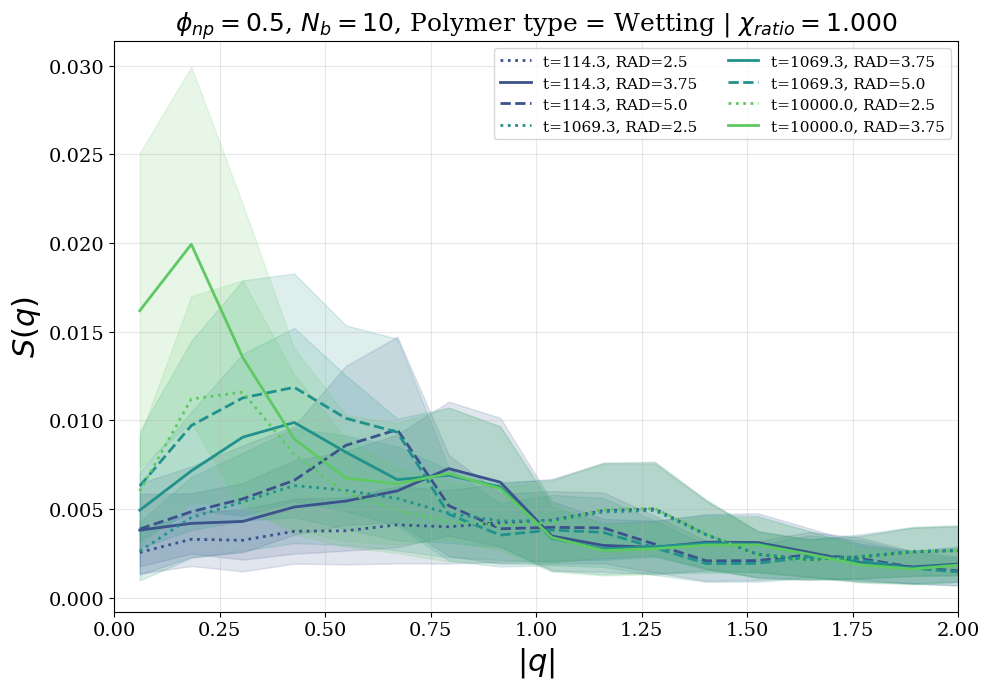

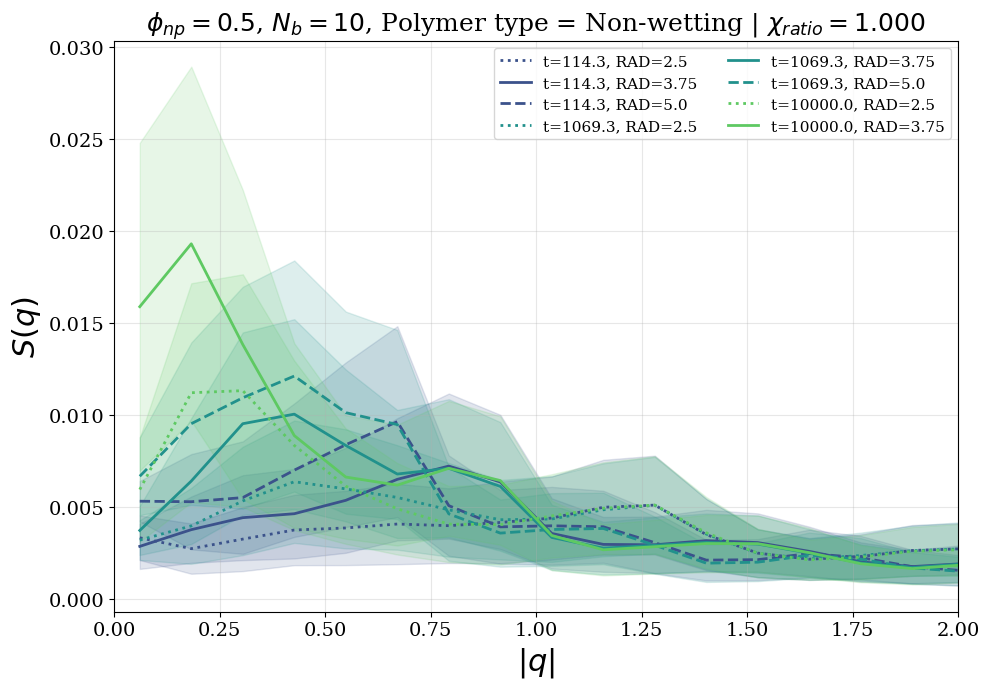

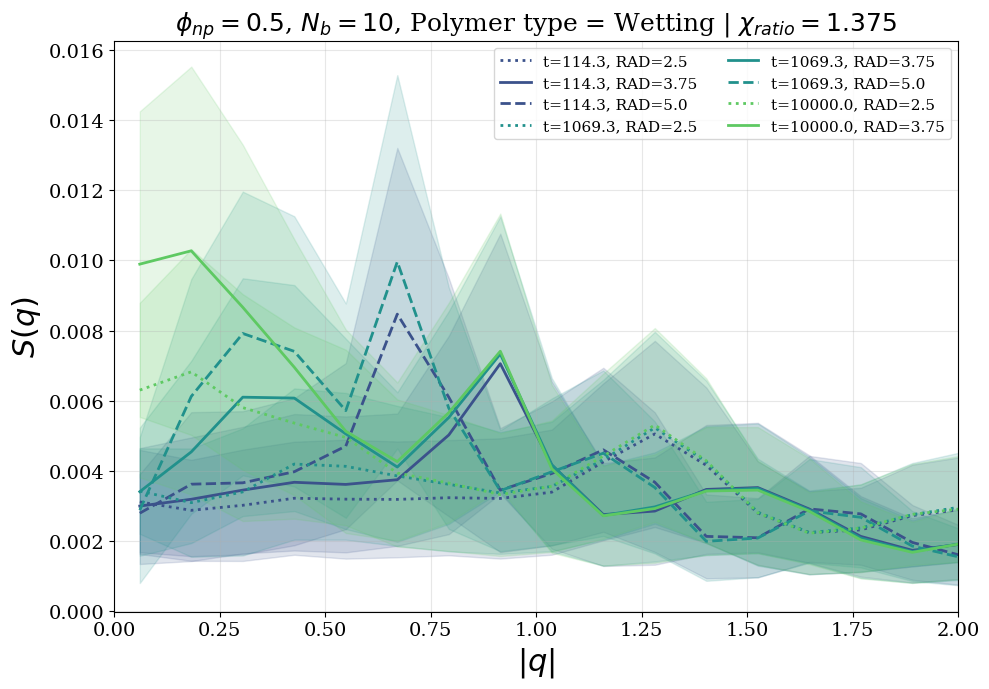

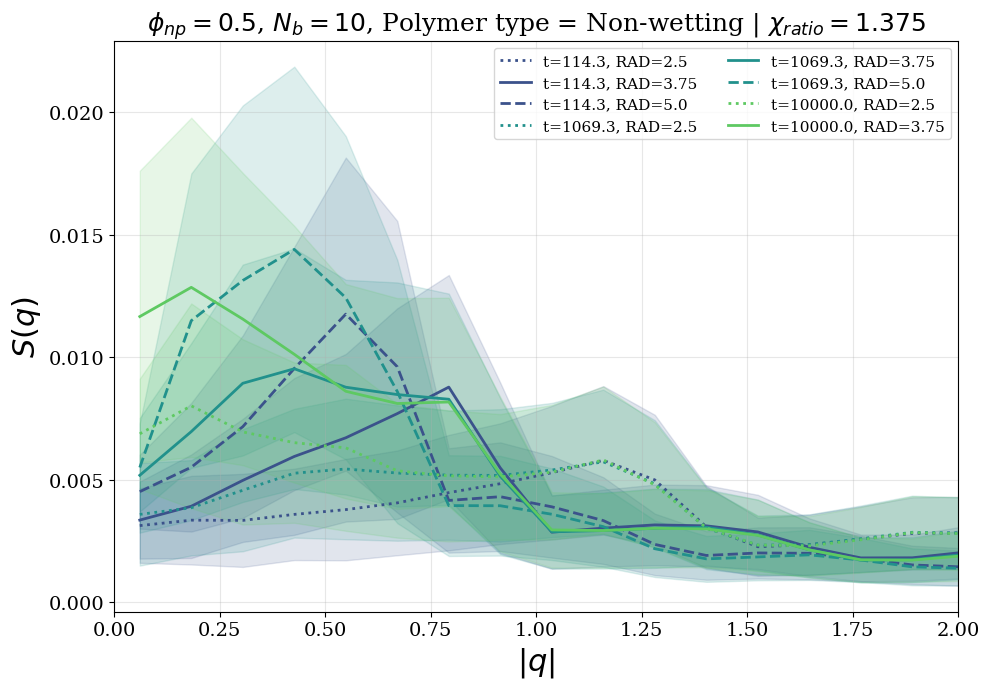

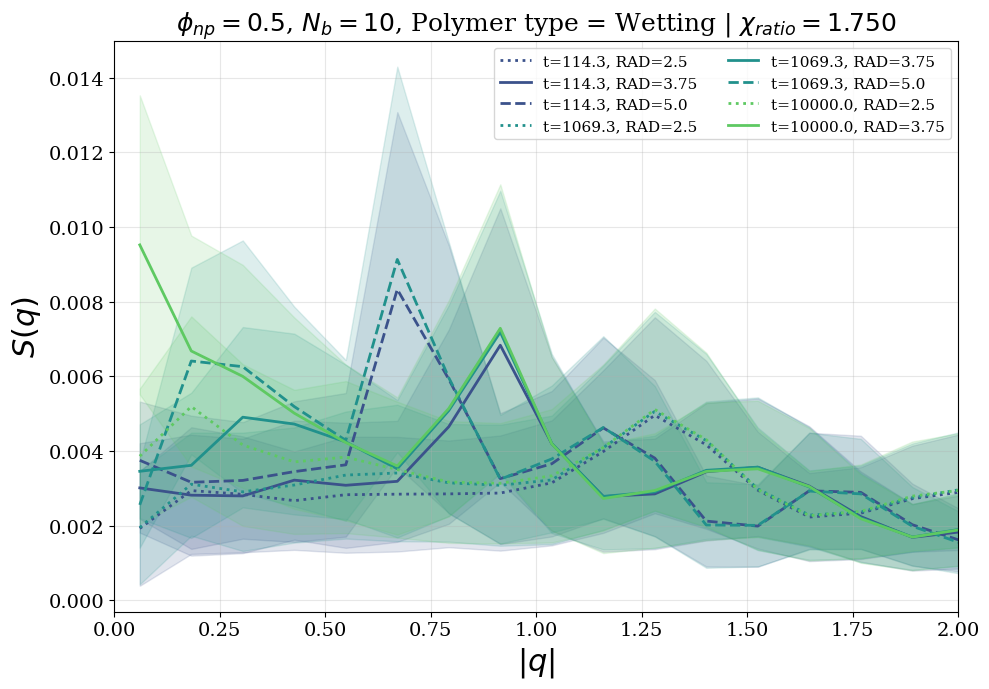

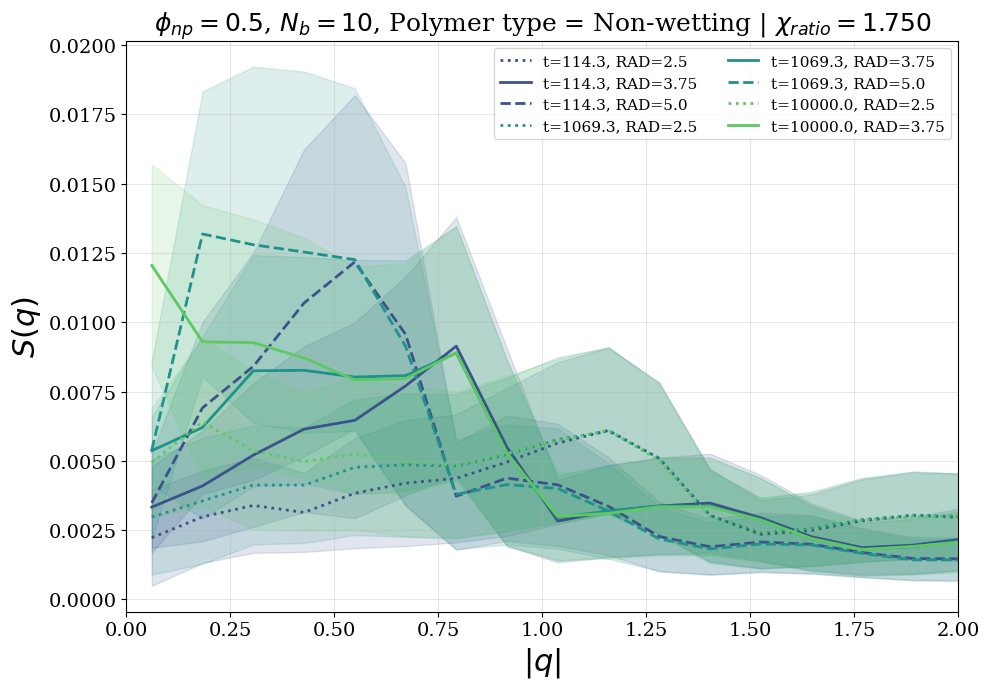

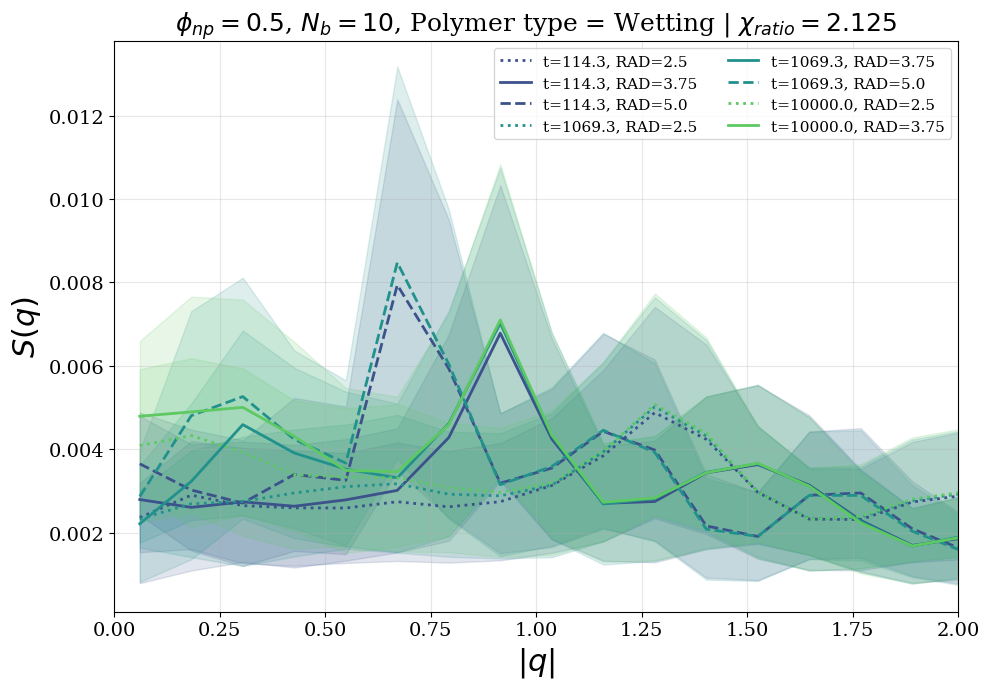

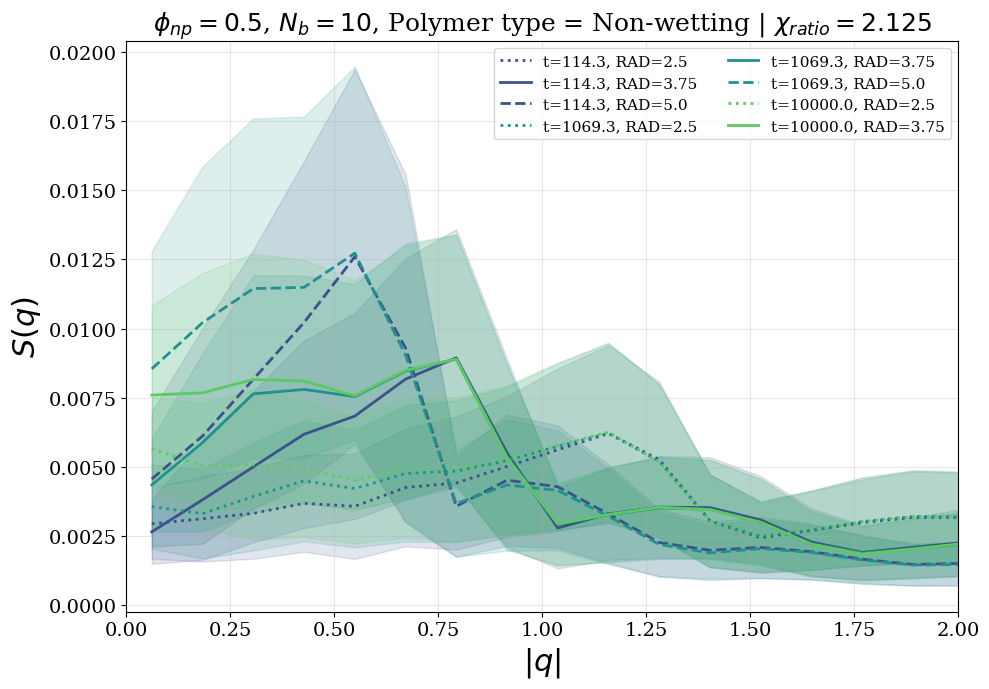

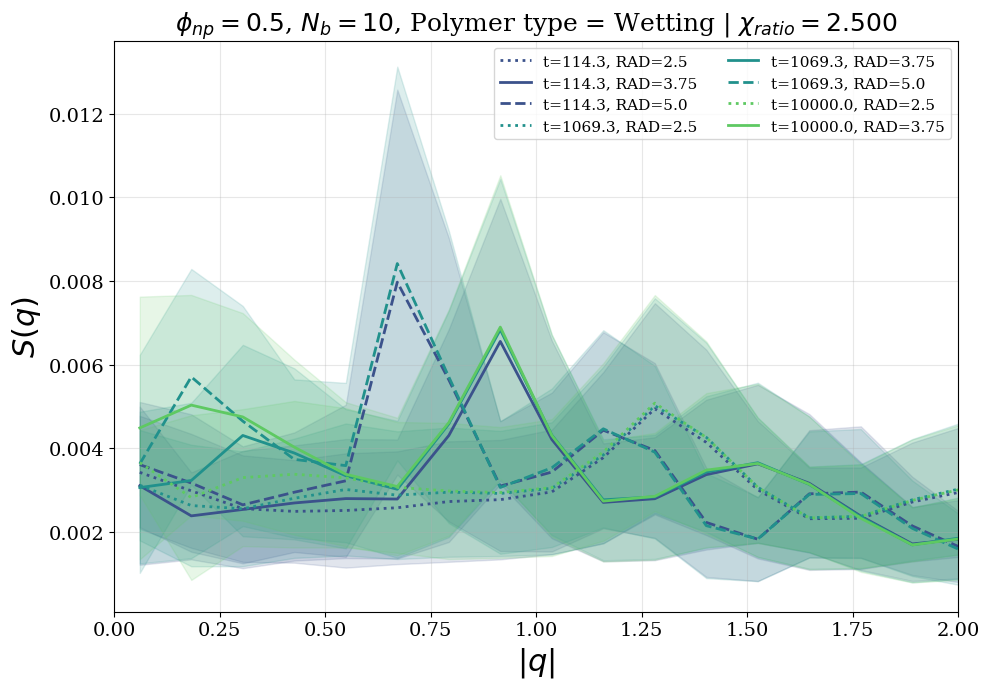

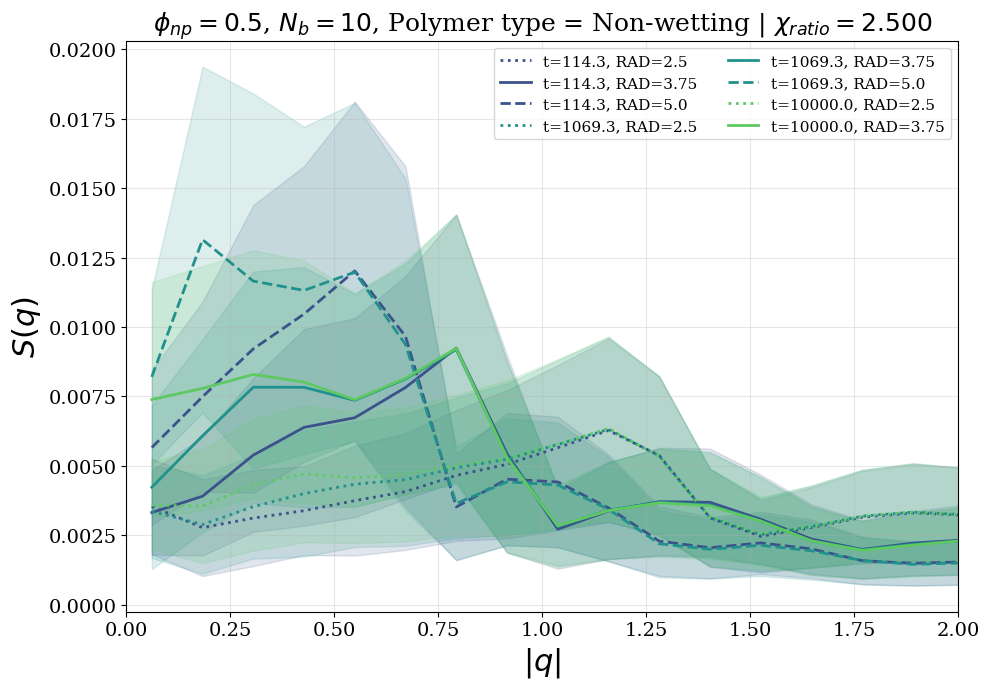

In [4]:
# Cell 4: Plot S(q) vs q

potentials_of_interest = [str(x) for x in sorted(data['POT'].unique())]
frames_of_interest     = [13, 23, 33]

filtered_data = data[
    data['POT'].isin(potentials_of_interest) &
    data['frame'].isin(frames_of_interest)
].copy()

grouped_data = filtered_data.groupby(['phi_np', 'POT', 'Nb', 'type'])

frame_colors      = sns.color_palette('viridis', len(frames_of_interest))
frame_color_map   = dict(zip(frames_of_interest, frame_colors))
radius_linestyles = {'2.5': ':', '3.75': '-', '5.0': '--'}
radius_labels     = {'2.5': 'RAD=2.5', '3.75': 'RAD=3.75', '5.0': 'RAD=5.0'}
poly_labels       = {'0': 'Wetting', '1': 'Non-wetting'}

for (phi_np, pot, nb, type_idx), group_data in grouped_data:
    plt.figure(figsize=(10, 7))
    radii = sorted(group_data['rad'].unique(), key=float)

    for frame in frames_of_interest:
        frame_data = group_data[group_data['frame'] == frame]
        if frame_data.empty:
            continue
        time_val = steps[int(frame)] * 0.005

        for rad in radii:
            rad_data = frame_data[frame_data['rad'] == rad]
            if rad_data.empty:
                continue

            k_c, sk_mean, sk_std, _ = bin_sk(
                rad_data['k'].values,
                rad_data['structure_factor'].values,
                L_BOX, k_max=2.0
            )

            ls         = radius_linestyles.get(rad, '-')
            color      = frame_color_map[frame]
            plot_label = f't={time_val:.1f}, {radius_labels.get(rad, rad)}'
            plt.plot(k_c, sk_mean,
                     linestyle=ls, color=color,
                     linewidth=2, label=plot_label)
            plt.fill_between(k_c, sk_mean - sk_std, sk_mean + sk_std,
                             color=color, alpha=0.15)

    pot_ratio = float(pot) / 10.0
    plt.title(
        rf'$\phi_{{np}}={phi_np}$, $N_b={nb}$, '
        rf'Polymer type = {poly_labels.get(str(type_idx), type_idx)} | '
        rf'$\chi_{{ratio}}={pot_ratio:.3f}$',
        fontsize=18
    )
    plt.xlabel(r'$|q|$', fontsize=22)
    plt.ylabel(r'$S(q)$', fontsize=22)
    plt.xlim(0.0, 2.0)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend(fontsize=11, frameon=True, ncol=2)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# Radial Density Profiles & Coordination Numbers

Radial density profiles g(r) of each polymer type around nanoparticle centers,
computed from production position binary files.
Coordination numbers obtained by integrating the first peak of g(r).

In [5]:
# Cell 10: Position-based analysis functions
# (All functions moved to Cell 2)

In [6]:
# Cell 11: Compute Radial Density Profiles (per frame, multiprocessing)

from multiprocessing import Pool

pos_directory = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Positions"

pos_pattern = re.compile(
    r"^PS_in_NP_frac_([\d.]+)_rad_([\d.]+)_POT_([\d.]+)_Nb_(\d+)_rep_(\d+)_positions\.bin$"
)

# Logarithmic timesteps (same as Cell 1)
steps = calculate_log_steps(max_steps, n_frames, freq)

skip = 9   # skip early frames


def _process_position_file(args):
    """Worker function for one position binary file."""
    fpath, fname, phi_np, rad, pot, nb, rep, steps, skip = args

    ns, Dim, L, tp, molID, frames = read_positions_bin(fpath)

    # Read Nx from the corresponding density file for grid-based dr
    dens_dir = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Density"
    dens_subfolder = f"NP_frac_{phi_np}_rad_{rad}_POT_{pot}_Nb_{nb}"
    dens_name = fname.replace("_positions.bin", "_densities.bin")
    dens_path = os.path.join(dens_dir, dens_subfolder, dens_name)
    if os.path.exists(dens_path):
        with open(dens_path, 'rb') as df:
            d_Dim = np.frombuffer(df.read(4), dtype=np.int32)[0]
            Nx_arr = np.frombuffer(df.read(4 * d_Dim), dtype=np.int32).copy()
    else:
        Nx_arr = np.array([81, 81, 81])

    file_results = []
    for frame_idx in range(skip, len(frames)):
        for poly_type in [0, 1]:
            r_mid, gr = compute_radial_density_profile(
                frames[frame_idx], L, tp, Nx_arr,
                np_type=2, poly_type=poly_type
            )
            n_poly   = int(np.sum(tp == poly_type))
            rho_bulk = n_poly / float(np.prod(L))

            file_results.append({
                'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
                'poly_type': poly_type, 'frame': frame_idx,
                'step': steps[frame_idx], 'time': steps[frame_idx] * 0.005,
                'r_mid': r_mid, 'gr': gr, 'rho_bulk': rho_bulk,
                'L': L.copy()
            })
    print(f"  Done: {fname}")
    return file_results


# Build task list
tasks = []
for fname in sorted(os.listdir(pos_directory)):
    m = pos_pattern.match(fname)
    if not m:
        continue
    phi_np, rad, pot, nb, rep = m.groups()
    fpath = os.path.join(pos_directory, fname)
    tasks.append((fpath, fname, phi_np, rad, pot, nb, rep, steps, skip))

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
hit_results, miss_tasks, miss_cps = [], [], []

for task in tasks:
    fpath_t, fname_t, phi_np_t, rad_t, pot_t, nb_t, rep_t, steps_t, skip_t = task
    cp = _cache_path('gr', phi_np_t, rad_t, pot_t, nb_t, rep_t, 'standard')
    if not FORCE_RECOMPUTE and cp.exists():
        hit_results.extend(_load_pkl(cp))
    else:
        miss_tasks.append(task)
        miss_cps.append(cp)

n_cached = len(tasks) - len(miss_tasks)
if miss_tasks:
    n_workers = choose_n_workers(len(miss_tasks))
    print(f"Computing {len(miss_tasks)} files with {n_workers} workers")
    with Pool(n_workers) as pool:
        new_results = pool.map(_process_position_file, miss_tasks)
    for file_res, cp in zip(new_results, miss_cps):
        _save_pkl(file_res, cp)
        hit_results.extend(file_res)

print(f"[cache] {n_cached} loaded, {len(miss_tasks)} computed")
results_gr = hit_results
print(f"\nTotal per-frame radial density profiles: {len(results_gr)}")


# ── NP-NP RDF ─────────────────────────────────────────────────────────────────

def _process_npnp_file(args):
    """Worker: compute NP-NP g(r) for all frames in one position file."""
    fpath, fname, phi_np, rad, pot, nb, rep, steps, skip = args

    ns, Dim, L, tp, molID, frames = read_positions_bin(fpath)

    dens_dir = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Density"
    dens_subfolder = f"NP_frac_{phi_np}_rad_{rad}_POT_{pot}_Nb_{nb}"
    dens_name = fname.replace("_positions.bin", "_densities.bin")
    dens_path = os.path.join(dens_dir, dens_subfolder, dens_name)
    if os.path.exists(dens_path):
        with open(dens_path, 'rb') as df:
            d_Dim  = np.frombuffer(df.read(4),         dtype=np.int32)[0]
            Nx_arr = np.frombuffer(df.read(4 * d_Dim), dtype=np.int32).copy()
    else:
        Nx_arr = np.array([81, 81, 81])

    file_results = []
    for frame_idx in range(skip, len(frames)):
        r_mid, gr = compute_np_np_rdf(frames[frame_idx], L, tp, Nx_arr, np_type=2)
        n_NP      = int(np.sum(tp == 2))
        file_results.append({
            'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
            'frame': frame_idx, 'step': steps[frame_idx],
            'time': steps[frame_idx] * 0.005,
            'r_mid': r_mid, 'gr': gr,
            'rho_bulk': n_NP / float(np.prod(L)), 'L': L.copy()
        })
    print(f"  Done (NP-NP): {fname}")
    return file_results


# Cache-aware dispatch for NP-NP RDF
hit_results_npnp, miss_tasks_npnp, miss_cps_npnp = [], [], []

for task in tasks:
    fpath_t, fname_t, phi_np_t, rad_t, pot_t, nb_t, rep_t, steps_t, skip_t = task
    cp = _cache_path('gr_npnp', phi_np_t, rad_t, pot_t, nb_t, rep_t, 'standard')
    if not FORCE_RECOMPUTE and cp.exists():
        hit_results_npnp.extend(_load_pkl(cp))
    else:
        miss_tasks_npnp.append(task)
        miss_cps_npnp.append(cp)

n_cached_npnp = len(tasks) - len(miss_tasks_npnp)
if miss_tasks_npnp:
    n_workers_npnp = choose_n_workers(len(miss_tasks_npnp))
    print(f"Computing NP-NP RDF for {len(miss_tasks_npnp)} files with {n_workers_npnp} workers")
    with Pool(n_workers_npnp) as pool:
        new_results_npnp = pool.map(_process_npnp_file, miss_tasks_npnp)
    for file_res, cp in zip(new_results_npnp, miss_cps_npnp):
        _save_pkl(file_res, cp)
        hit_results_npnp.extend(file_res)

print(f"[cache] NP-NP RDF: {n_cached_npnp} loaded, {len(miss_tasks_npnp)} computed")
results_gr_npnp = hit_results_npnp
print(f"Total NP-NP RDF frames: {len(results_gr_npnp)}")


[cache] 45 loaded, 0 computed

Total per-frame radial density profiles: 2220
[cache] NP-NP RDF: 45 loaded, 0 computed
Total NP-NP RDF frames: 1110


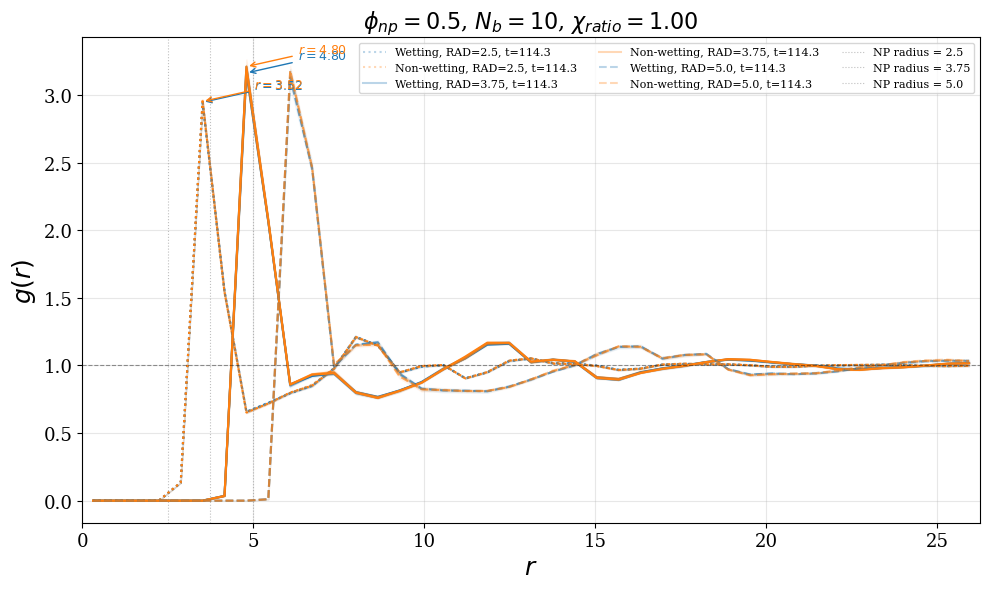

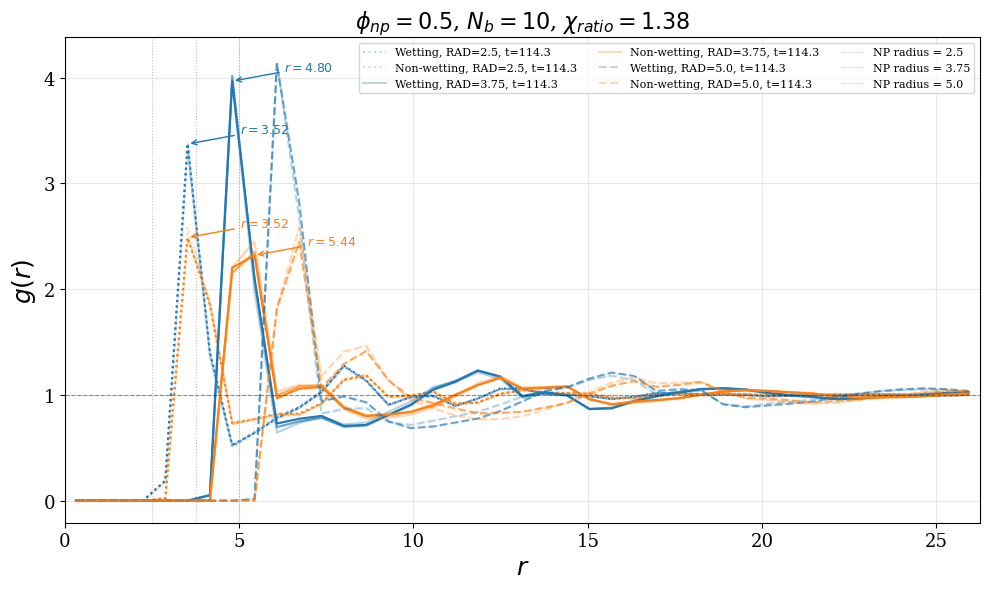

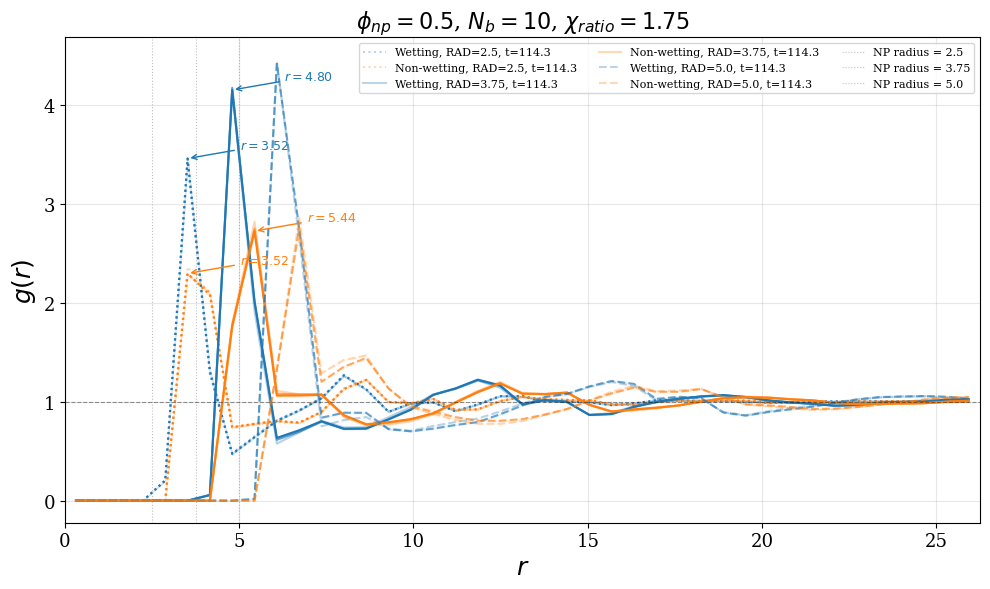

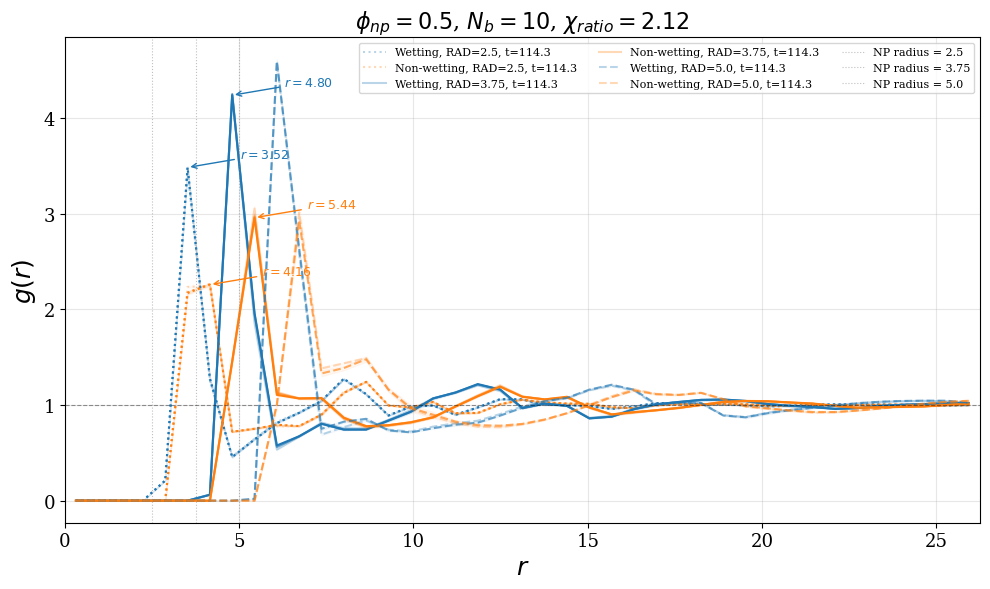

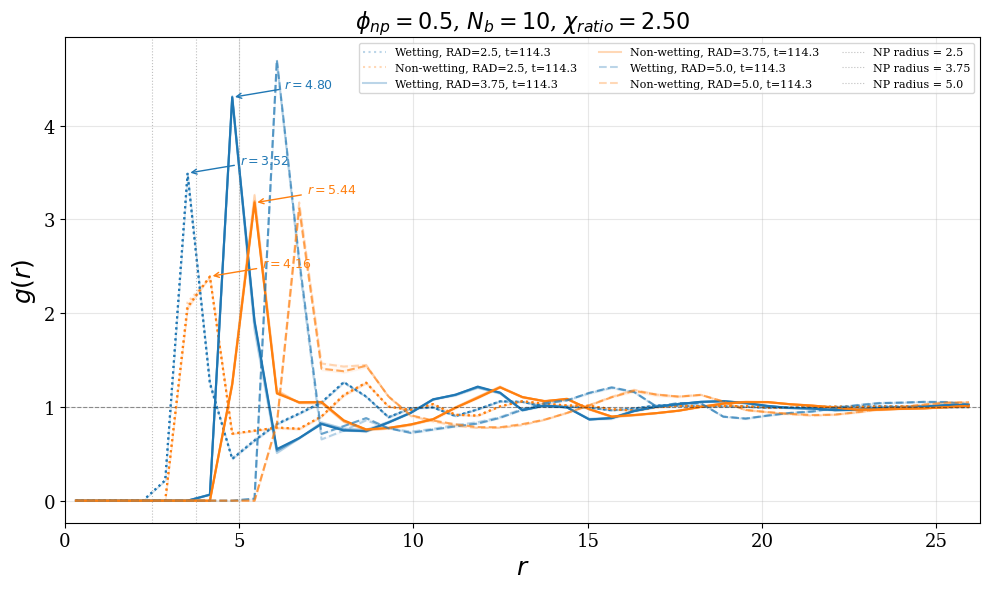

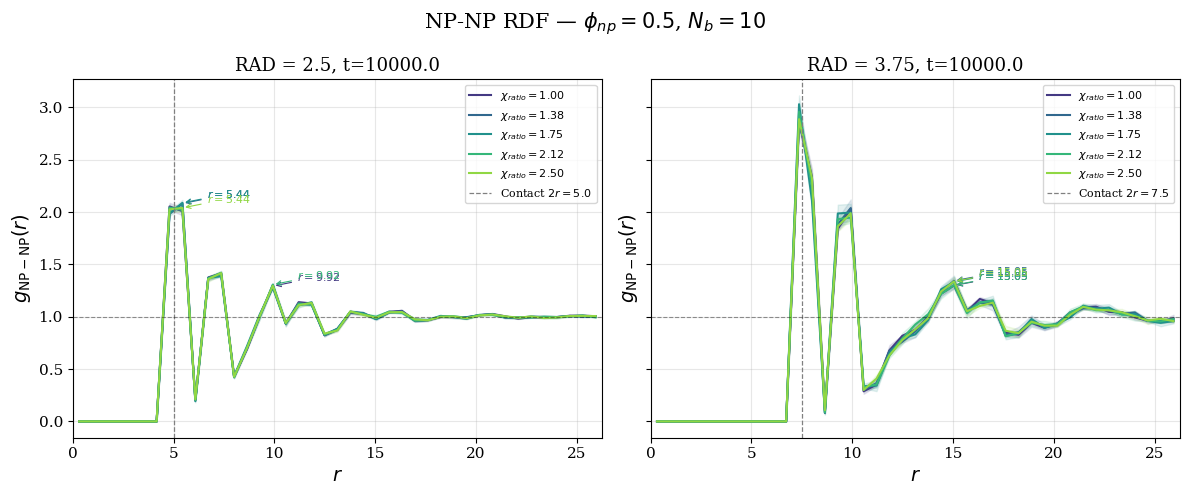

In [7]:
# Cell 11b: Plot Radial Density Profiles
# One figure per (phi_np, Nb, POT): all radii overlaid via linestyle,
# both polymer types via color, frames via alpha.

from collections import defaultdict
from scipy.signal import argrelextrema

poly_labels   = {0: 'Wetting', 1: 'Non-wetting'}
poly_colors   = {0: 'tab:blue', 1: 'tab:orange'}
radius_linestyles = {'2.5': ':', '3.75': '-', '5.0': '--'}

frames_of_interest = [13, 23, 33]
final_frame = max(frames_of_interest)
frame_alphas = {f: 0.3 + 0.7 * (i / (len(frames_of_interest) - 1))
                for i, f in enumerate(frames_of_interest)}

# Group results by (phi_np, Nb, POT, rad, poly_type, frame) — average over reps
avg_gr = {}
by_key = defaultdict(list)
for res in results_gr:
    if res['frame'] in frames_of_interest:
        key = (res['phi_np'], res['Nb'], res['POT'], res['rad'],
               res['poly_type'], res['frame'])
        by_key[key].append(res)

for key, res_list in by_key.items():
    gr_arr = np.array([r['gr'] for r in res_list])
    avg_gr[key] = {
        'r_mid':   res_list[0]['r_mid'],
        'gr_mean': gr_arr.mean(axis=0),
        'gr_std':  gr_arr.std(axis=0),
        'time':    res_list[0]['time'],
        'L':       res_list[0]['L'],
    }

# Unique plot groups: (phi_np, Nb, POT)
plot_keys = sorted(set(k[:3] for k in avg_gr.keys()))

for (phi_np, nb, pot) in plot_keys:
    chi = float(pot) / 10.0
    fig, ax = plt.subplots(figsize=(10, 6))

    rads = sorted(set(k[3] for k in avg_gr if k[:3] == (phi_np, nb, pot)), key=float)

    for rad in rads:
        ls = radius_linestyles.get(rad, '-')

        for poly_type in [0, 1]:
            color = poly_colors[poly_type]

            for frame_idx in frames_of_interest:
                key = (phi_np, nb, pot, rad, poly_type, frame_idx)
                if key not in avg_gr:
                    continue
                d = avg_gr[key]
                r_mid    = d['r_mid']
                gr_mean  = d['gr_mean']
                gr_std   = d['gr_std']
                time_val = d['time']
                alpha    = frame_alphas[frame_idx]

                plot_label = (rf'{poly_labels[poly_type]}, RAD={rad}, t={time_val:.1f}'
                              if frame_idx == frames_of_interest[0] else None)
                ax.plot(r_mid, gr_mean,
                        color=color, alpha=alpha, lw=1.5,
                        linestyle=ls, label=plot_label)
                ax.fill_between(r_mid, gr_mean - gr_std, gr_mean + gr_std,
                                color=color, alpha=0.08 * alpha)

                # Annotate first peak of the final frame
                if frame_idx == final_frame:
                    rad_val = float(rad)
                    mask  = r_mid > rad_val
                    r_sub = r_mid[mask]
                    g_sub = gr_mean[mask]
                    peaks = argrelextrema(g_sub, np.greater, order=5)[0]
                    if len(peaks) > 0:
                        r_peak = r_sub[peaks[0]]
                        g_peak = g_sub[peaks[0]]
                        ax.annotate(
                            rf'$r={r_peak:.2f}$',
                            xy=(r_peak, g_peak),
                            xytext=(r_peak + 1.5, g_peak + 0.1),
                            fontsize=9, color=color,
                            arrowprops=dict(arrowstyle='->', color=color, lw=1.0),
                        )

    # Reference lines for each NP radius
    for rad in rads:
        ax.axvline(float(rad), color='gray', ls=':', lw=0.8, alpha=0.5,
                   label=f'NP radius = {rad}')

    ax.axhline(1.0, color='k', ls='--', lw=0.8, alpha=0.4)
    ax.set_xlabel(r'$r$', fontsize=18)
    ax.set_ylabel(r'$g(r)$', fontsize=18)
    ax.set_title(
        rf'$\phi_{{np}}={phi_np}$, $N_b={nb}$, $\chi_{{ratio}}={chi:.2f}$',
        fontsize=16
    )
    ax.legend(fontsize=8, frameon=True, ncol=3)
    ax.tick_params(labelsize=13)
    ax.grid(alpha=0.3)
    # x limit: half-box of smallest system
    all_L = [avg_gr[(phi_np, nb, pot, rad, 0, frames_of_interest[0])]['L'].min()
             for rad in rads
             if (phi_np, nb, pot, rad, 0, frames_of_interest[0]) in avg_gr]
    if all_L:
        ax.set_xlim(0, min(all_L) / 2.0)
    fig.tight_layout()
    plt.show()


# ── NP-NP RDF plots ───────────────────────────────────────────────────────────
# One figure per (phi_np, Nb): one subplot per NP radius, POTs colour-coded.
# Shown at the final frame of interest to highlight steady-state clustering.

final_frame_npnp = frames_of_interest[-1]

avg_gr_npnp = {}
by_key_npnp = defaultdict(list)
for res in results_gr_npnp:
    if res['frame'] == final_frame_npnp:
        key = (res['phi_np'], res['Nb'], res['POT'], res['rad'])
        by_key_npnp[key].append(res)

for key, res_list in by_key_npnp.items():
    gr_arr = np.array([r['gr'] for r in res_list])
    avg_gr_npnp[key] = {
        'r_mid':   res_list[0]['r_mid'],
        'gr_mean': gr_arr.mean(axis=0),
        'gr_std':  gr_arr.std(axis=0),
        'time':    res_list[0]['time'],
        'L':       res_list[0]['L'],
    }

npnp_plot_groups = sorted(set((k[0], k[1]) for k in avg_gr_npnp))

for (phi_np, nb) in npnp_plot_groups:
    pots_np = sorted(set(k[2] for k in avg_gr_npnp if k[0] == phi_np and k[1] == nb),
                     key=float)
    rads_np = sorted(set(k[3] for k in avg_gr_npnp if k[0] == phi_np and k[1] == nb),
                     key=float)
    pot_colors_np = sns.color_palette('viridis', len(pots_np))
    pot_color_map_np = dict(zip(pots_np, pot_colors_np))

    fig, axes = plt.subplots(1, len(rads_np),
                             figsize=(6 * len(rads_np), 5),
                             sharey=True, squeeze=False)

    for ax, rad in zip(axes[0], rads_np):
        rad_val     = float(rad)
        contact_r   = 2.0 * rad_val

        for pot in pots_np:
            key = (phi_np, nb, pot, rad)
            if key not in avg_gr_npnp:
                continue
            d     = avg_gr_npnp[key]
            chi   = float(pot) / 10.0
            color = pot_color_map_np[pot]

            ax.plot(d['r_mid'], d['gr_mean'],
                    color=color, lw=1.5,
                    label=rf'$\chi_{{ratio}}={chi:.2f}$')
            ax.fill_between(d['r_mid'],
                            d['gr_mean'] - d['gr_std'],
                            d['gr_mean'] + d['gr_std'],
                            color=color, alpha=0.12)

            # Annotate first peak near/beyond the contact distance
            mask_peak = d['r_mid'] > contact_r * 0.9
            r_sub = d['r_mid'][mask_peak]
            g_sub = d['gr_mean'][mask_peak]
            peaks = argrelextrema(g_sub, np.greater, order=3)[0]
            if len(peaks) > 0:
                r_pk = r_sub[peaks[0]]
                g_pk = g_sub[peaks[0]]
                ax.annotate(rf'$r={r_pk:.2f}$',
                            xy=(r_pk, g_pk),
                            xytext=(r_pk + 1.2, g_pk + 0.05),
                            fontsize=8, color=color,
                            arrowprops=dict(arrowstyle='->', color=color, lw=0.8))

        ax.axvline(contact_r, color='gray', ls='--', lw=0.9,
                   label=rf'Contact $2r={contact_r}$')
        ax.axhline(1.0, color='k', ls='--', lw=0.8, alpha=0.4)
        ax.set_xlabel(r'$r$', fontsize=14)
        ax.set_ylabel(r'$g_{\mathrm{NP-NP}}(r)$', fontsize=14)

        d_ref = avg_gr_npnp.get((phi_np, nb, pots_np[0], rad))
        t_str = f', t={d_ref["time"]:.1f}' if d_ref else ''
        ax.set_title(f'RAD = {rad}{t_str}', fontsize=13)
        ax.legend(fontsize=8, frameon=True)
        ax.tick_params(labelsize=11)
        ax.grid(alpha=0.3)
        if d_ref is not None:
            ax.set_xlim(0, float(d_ref['L'].min()) / 2.0)

    fig.suptitle(rf'NP-NP RDF — $\phi_{{np}}={phi_np}$, $N_b={nb}$', fontsize=15)
    fig.tight_layout()
    plt.show()


[cache] Loaded coordination numbers (2220 rows)


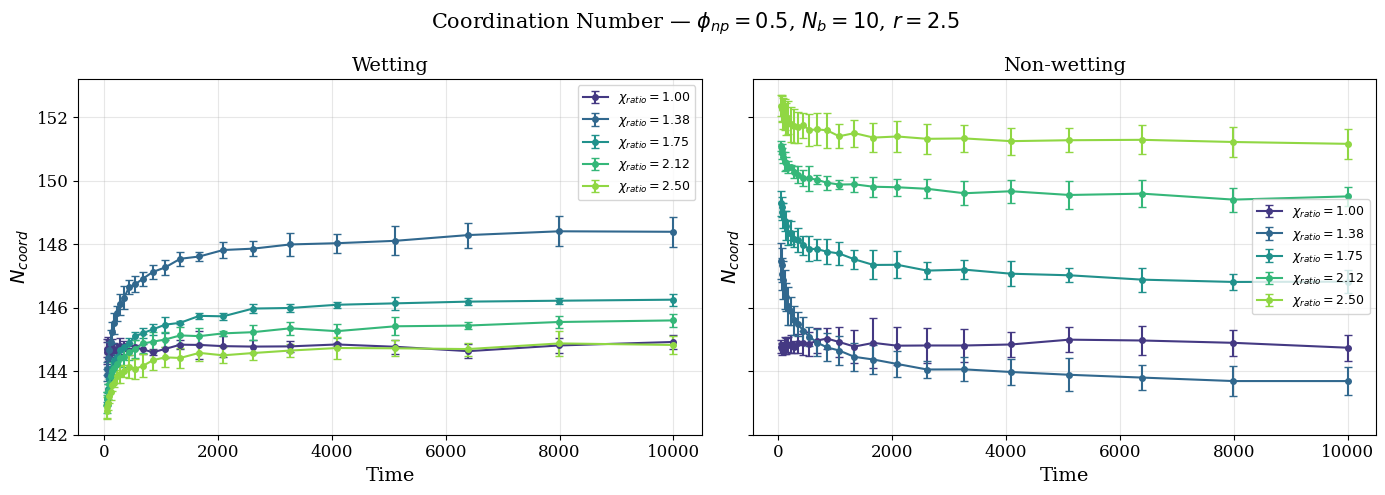

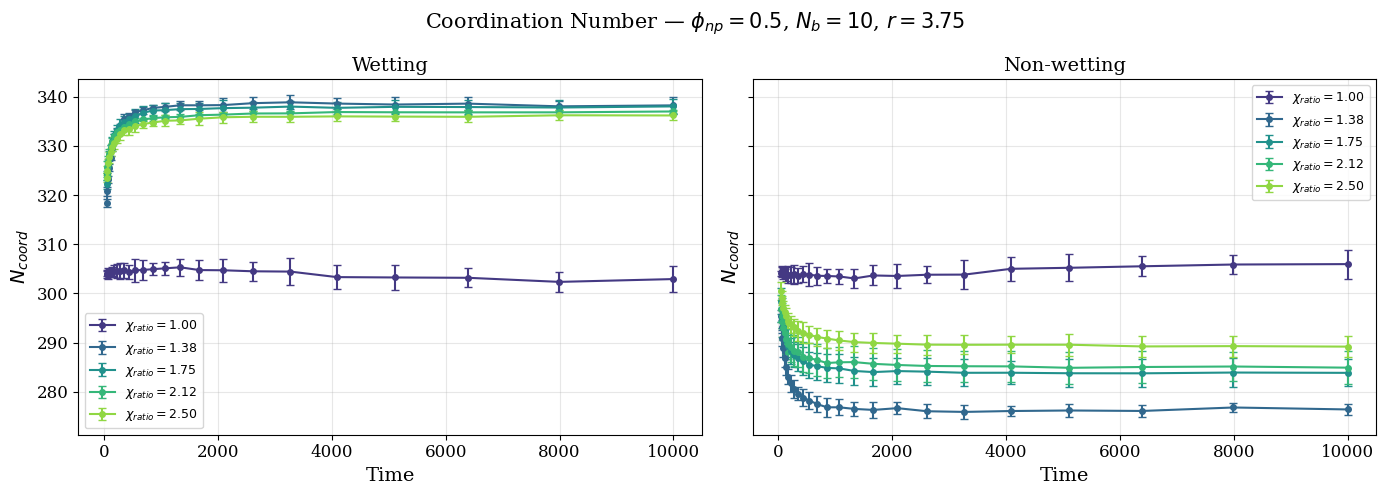

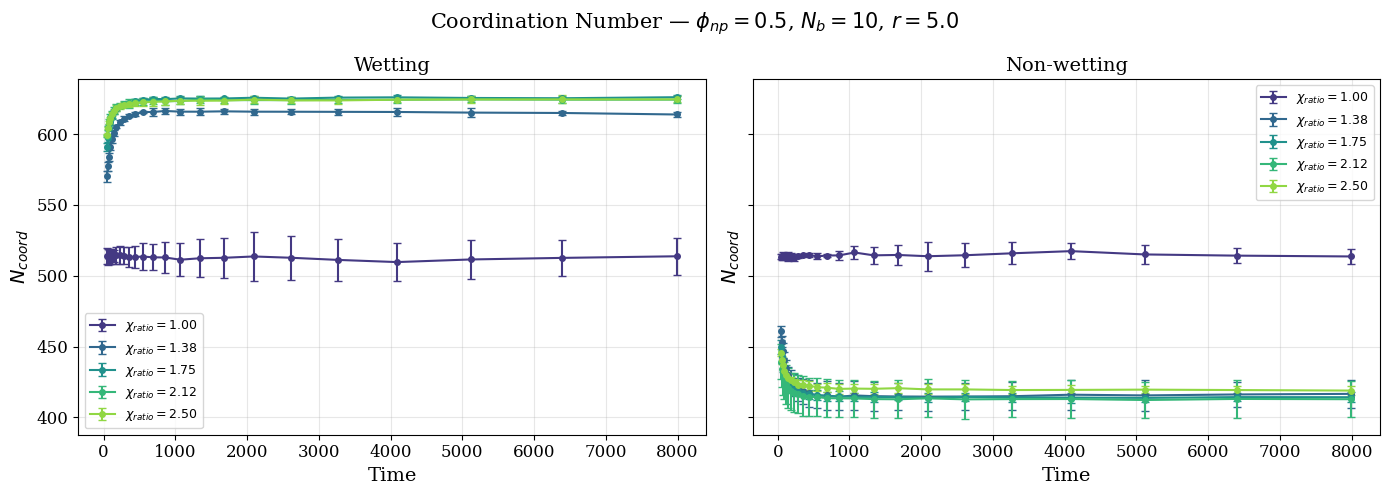


Coordination numbers at final frame (33):

                                N_coord_mean  N_coord_std  r_min_mean
phi_np rad  POT   Nb poly_type                                       
0.5    2.5  10.0  10 0                144.92         0.22        4.80
                     1                144.74         0.41        4.80
            13.75 10 0                148.39         0.47        4.80
                     1                143.69         0.45        4.80
            17.5  10 0                146.25         0.18        4.80
                     1                146.82         0.37        4.80
            21.25 10 0                145.60         0.21        4.80
                     1                149.50         0.29        4.80
            25.0  10 0                144.83         0.28        4.80
                     1                151.16         0.46        4.80
       3.75 10.0  10 0                302.91         2.62        6.08
                     1                305.95  

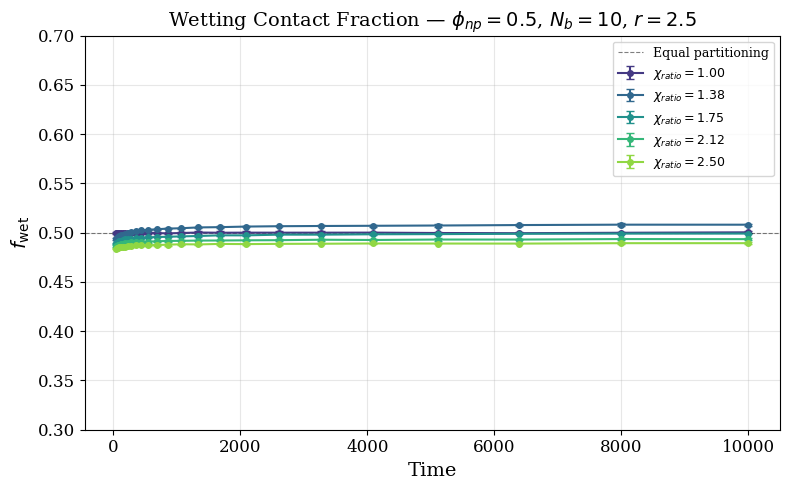

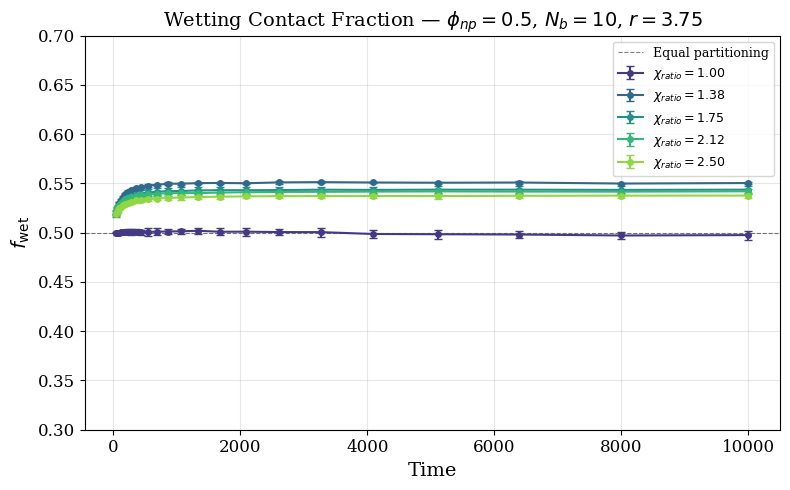

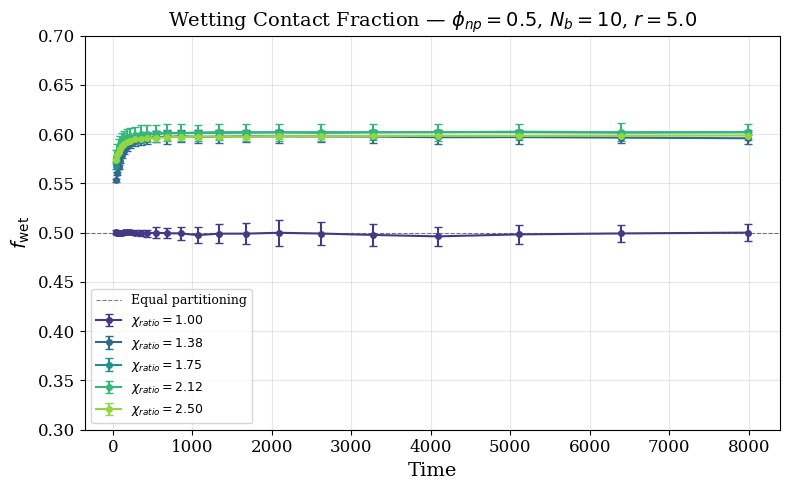

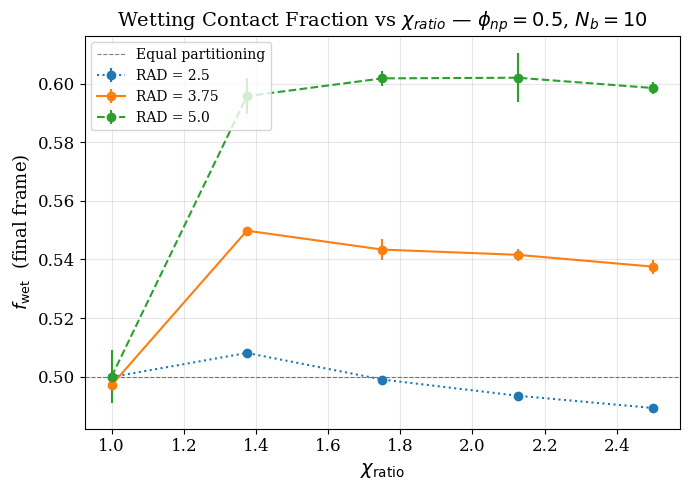

In [8]:
# Cell 12: Coordination Numbers (per frame)
# Uses r_min from the wetting polymer (type 0) g(r) for both polymer types.

_coord_cache = CACHE_DIR / "coord_all_runs.pkl"
if not FORCE_RECOMPUTE and _coord_cache.exists():
    coord_df = _load_pkl(_coord_cache)
    print(f"[cache] Loaded coordination numbers ({len(coord_df)} rows)")
else:
    from collections import defaultdict

    # ── First pass: determine r_min from wetting polymer g(r) ────────────────────
    # Key: (phi_np, rad, POT, Nb, rep, frame) -> r_min
    wetting_rmin = {}

    for res in results_gr:
        if res['poly_type'] != 0:
            continue
        r_mid    = res['r_mid']
        gr       = res['gr']
        rad_val  = float(res['rad']) + 1.0

        r_min = find_first_minimum(r_mid, gr, r_start=rad_val, r_end=12.0, order=1)
        if r_min is None:
            r_min = rad_val + 3.0  # fallback

        key = (res['phi_np'], res['rad'], res['POT'], res['Nb'], res['rep'], res['frame'])
        wetting_rmin[key] = r_min

    # ── Second pass: compute coordination numbers using wetting r_min ─────────────
    coord_results = []

    for res in results_gr:
        r_mid    = res['r_mid']
        gr       = res['gr']
        rho_bulk = res['rho_bulk']

        key = (res['phi_np'], res['rad'], res['POT'], res['Nb'], res['rep'], res['frame'])
        r_min = wetting_rmin[key]

        n_coord = coordination_number(r_mid, gr, rho_bulk, r_min)

        coord_results.append({
            'phi_np': res['phi_np'], 'rad': res['rad'], 'POT': res['POT'],
            'Nb': res['Nb'], 'rep': res['rep'], 'poly_type': res['poly_type'],
            'frame': res['frame'], 'step': res['step'], 'time': res['time'],
            'r_min': r_min, 'N_coord': n_coord
        })

    coord_df = pd.DataFrame(coord_results)
    coord_df['chi_ratio'] = coord_df['POT'].astype(float) / 10.0
    _save_pkl(coord_df, _coord_cache)
    print(f"[cache] Saved coordination numbers ({len(coord_df)} rows)")

# ── Plot: coordination number vs time for each (phi_np, Nb, POT) ─────────────
pot_list = sorted(coord_df['POT'].unique(), key=float)
pot_colors_coord = sns.color_palette('viridis', len(pot_list))
pot_color_map_coord = dict(zip(pot_list, pot_colors_coord))

for (phi_np, nb, rad), sub_df in coord_df.groupby(['phi_np', 'Nb', 'rad']):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

    for ax, poly_type in zip(axes, [0, 1]):
        pt_df = sub_df[sub_df['poly_type'] == poly_type]

        for pot, pot_df in pt_df.groupby('POT'):
            stats = pot_df.groupby('time')['N_coord'].agg(['mean', 'std']).reset_index()
            chi = float(pot) / 10.0
            color = pot_color_map_coord[pot]
            ax.errorbar(stats['time'], stats['mean'], yerr=stats['std'],
                        marker='o', ms=4, color=color, capsize=3,
                        label=rf'$\chi_{{ratio}}={chi:.2f}$')

        ax.set_xlabel('Time', fontsize=14)
        ax.set_ylabel(r'$N_{coord}$', fontsize=14)
        ax.set_title(f'{poly_labels[poly_type]}', fontsize=14)
        ax.legend(fontsize=9, frameon=True)
        ax.tick_params(labelsize=12)
        ax.grid(alpha=0.3)

    fig.suptitle(rf'Coordination Number — $\phi_{{np}}={phi_np}$, $N_b={nb}$, $r={rad}$', fontsize=15)
    fig.tight_layout()
    plt.show()

# ── Summary table using last frame only ───────────────────────────────────────
last_frame = coord_df['frame'].max()
print(f"\nCoordination numbers at final frame ({last_frame}):\n")
print(coord_df[coord_df['frame'] == last_frame]
      [['phi_np', 'rad', 'POT', 'Nb', 'poly_type', 'r_min', 'N_coord']]
      .groupby(['phi_np', 'rad', 'POT', 'Nb', 'poly_type'])
      .agg(N_coord_mean=('N_coord', 'mean'), N_coord_std=('N_coord', 'std'),
           r_min_mean=('r_min', 'mean'))
      .round(2)
      .to_string())

# ── Wetting contact fraction ──────────────────────────────────────────────────
# f_wet = N_coord(type 0) / (N_coord(type 0) + N_coord(type 1))
# Values > 0.5 mean wetting polymer dominates the NP contact shell.

coord_pivot = (
    coord_df
    .pivot_table(
        index=['phi_np', 'rad', 'POT', 'Nb', 'rep', 'frame', 'time'],
        columns='poly_type',
        values='N_coord'
    )
    .reset_index()
)
coord_pivot.columns.name = None
coord_pivot = coord_pivot.rename(columns={0: 'N_wet', 1: 'N_nonwet'})
coord_pivot['f_wet'] = coord_pivot['N_wet'] / (coord_pivot['N_wet'] + coord_pivot['N_nonwet'])

# Time evolution per (phi_np, Nb, rad)
for (phi_np, nb, rad), sub_df in coord_pivot.groupby(['phi_np', 'Nb', 'rad']):
    fig, ax = plt.subplots(figsize=(8, 5))

    for pot, pot_df in sub_df.groupby('POT'):
        stats = pot_df.groupby('time')['f_wet'].agg(['mean', 'std']).reset_index()
        chi   = float(pot) / 10.0
        color = pot_color_map_coord[pot]
        ax.errorbar(stats['time'], stats['mean'], yerr=stats['std'],
                    marker='o', ms=4, color=color, capsize=3,
                    label=rf'$\chi_{{ratio}}={chi:.2f}$')

    ax.axhline(0.5, color='k', ls='--', lw=0.8, alpha=0.5, label='Equal partitioning')
    ax.set_xlabel('Time', fontsize=14)
    ax.set_ylabel(r'$f_{\mathrm{wet}}$', fontsize=14)
    ax.set_title(
        rf'Wetting Contact Fraction — $\phi_{{np}}={phi_np}$, $N_b={nb}$, $r={rad}$',
        fontsize=14
    )
    ax.set_ylim(0.3, 0.7)
    ax.legend(fontsize=9, frameon=True)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

# Final-frame summary: f_wet vs chi_ratio, one curve per rad
last_f      = coord_pivot['frame'].max()
coord_final = coord_pivot[coord_pivot['frame'] == last_f-1]
fwet_stats  = (
    coord_final
    .groupby(['phi_np', 'Nb', 'rad', 'POT'])['f_wet']
    .agg(f_wet_mean='mean', f_wet_std='std')
    .reset_index()
)

for phi_np in sorted(fwet_stats['phi_np'].unique()):
    for nb in sorted(fwet_stats['Nb'].unique()):
        sub = fwet_stats[
            (fwet_stats['phi_np'] == phi_np) & (fwet_stats['Nb'] == nb)
        ]
        if sub.empty:
            continue

        fig, ax = plt.subplots(figsize=(7, 5))

        for rad in sorted(sub['rad'].unique(), key=float):
            rs = sub[sub['rad'] == rad].sort_values(
                'POT', key=lambda x: x.astype(float)
            )
            chi_x = rs['POT'].astype(float) / 10.0
            ax.errorbar(chi_x, rs['f_wet_mean'], yerr=rs['f_wet_std'],
                        marker='o', ms=6, lw=1.5,
                        linestyle=radius_linestyles.get(rad, '-'),
                        label=f'RAD = {rad}')

        ax.axhline(0.5, color='k', ls='--', lw=0.8, alpha=0.5,
                   label='Equal partitioning')
        ax.set_xlabel(r'$\chi_{\mathrm{ratio}}$', fontsize=14)
        ax.set_ylabel(r'$f_{\mathrm{wet}}$  (final frame)', fontsize=13)
        ax.set_title(
            rf'Wetting Contact Fraction vs $\chi_{{ratio}}$ — '
            rf'$\phi_{{np}}={phi_np}$, $N_b={nb}$',
            fontsize=14
        )
        ax.legend(fontsize=10, frameon=True)
        ax.tick_params(labelsize=12)
        ax.grid(alpha=0.3)
        fig.tight_layout()
        plt.show()


# Local Density Distributions

Polymer density distributions computed by coarse-graining the density grid
into voxels of side length ~1.3 (2 grid points per axis).

[cache] 45 loaded, 0 computed
Total density fraction distributions: 45 files


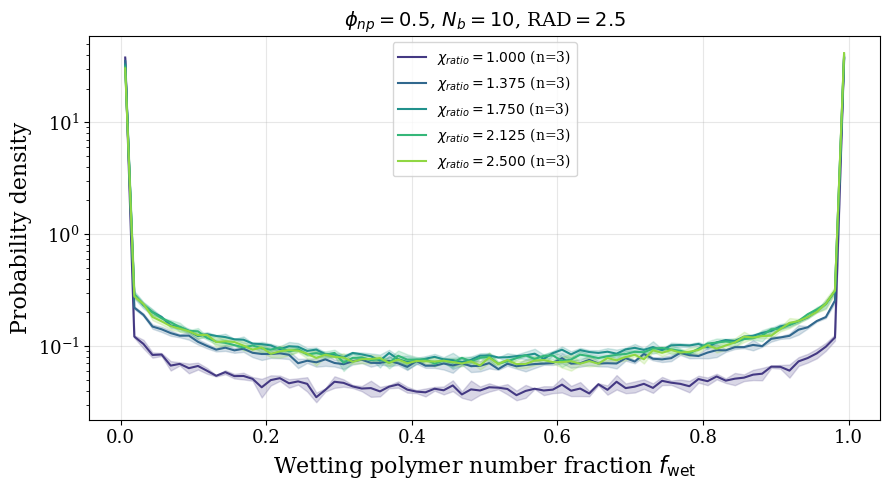

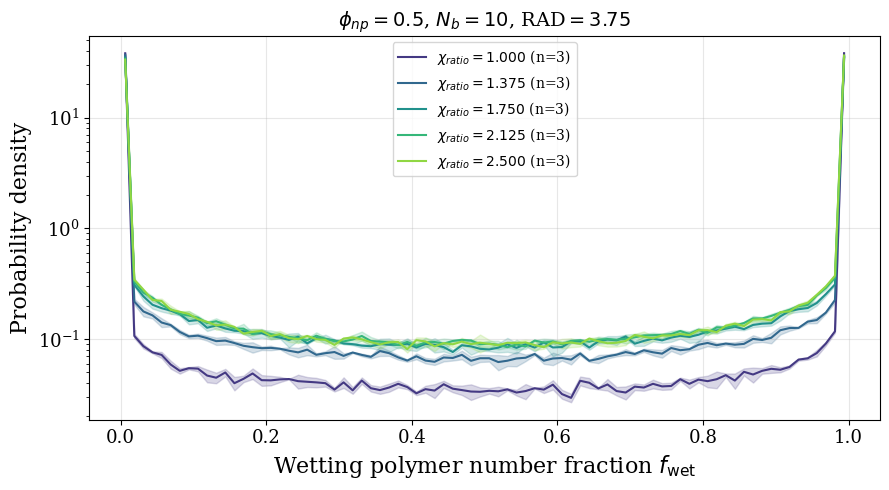

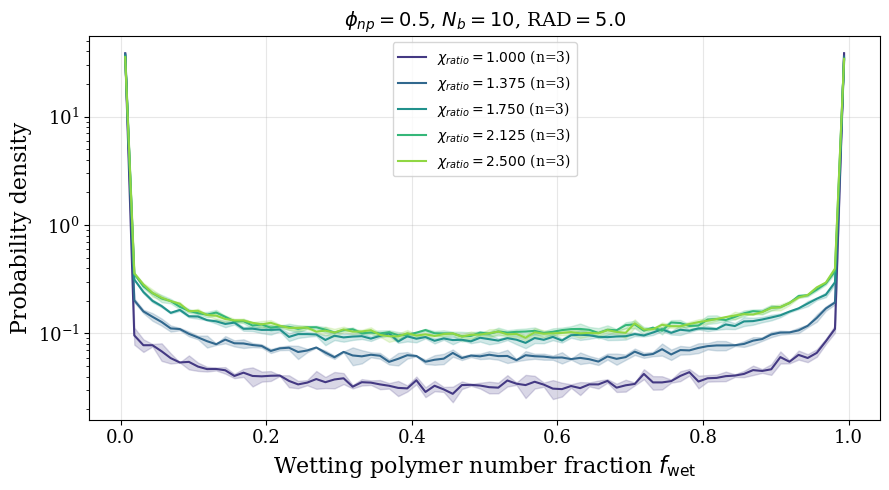

In [9]:
# Cell 14: Number Fraction Distributions from Density Grid
# Number fraction f_wet = rho_0 / (rho_0 + rho_1) is insensitive to
# compressibility (unlike raw density), so it directly tracks phase separation.

from multiprocessing import Pool
from collections import defaultdict

density_directory = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Density"

density_pattern = re.compile(
    r"^PS_in_NP_frac_([\d.]+)_rad_([\d.]+)_POT_([\d.]+)_Nb_(\d+)_rep_(\d+)_densities\.bin$"
)


def _process_density_file(args):
    """
    Worker: compute per-voxel wetting number fraction for the last frame.

    f_wet = rho_0 / (rho_0 + rho_1), restricted to voxels with non-negligible
    polymer density (total > 0.05) to exclude NP-dominated or vacuum voxels.
    """
    fpath, phi_np, rad, pot, nb, rep = args
    _, _, _, rho = read_density_fields(fpath)

    rho_wet = rho[0].ravel().astype(np.float64)
    rho_nw  = rho[1].ravel().astype(np.float64)
    total   = rho_wet + rho_nw
    valid   = total > 0.05
    f_wet   = rho_wet[valid] / total[valid]

    return [{'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
             'f_wet': f_wet}]


# Build task list
dens_tasks = []
for subfolder in sorted(os.listdir(density_directory)):
    sub_path = os.path.join(density_directory, subfolder)
    if not os.path.isdir(sub_path):
        continue
    for fname in sorted(os.listdir(sub_path)):
        m = density_pattern.match(fname)
        if not m:
            continue
        phi_np, rad, pot, nb, rep = m.groups()
        dens_tasks.append((os.path.join(sub_path, fname), phi_np, rad, pot, nb, rep))

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
hit_results, miss_tasks, miss_cps = [], [], []

for task in dens_tasks:
    fpath_t, phi_np_t, rad_t, pot_t, nb_t, rep_t = task
    cp = _cache_path('density_frac', phi_np_t, rad_t, pot_t, nb_t, rep_t, 'standard')
    if not FORCE_RECOMPUTE and cp.exists():
        hit_results.extend(_load_pkl(cp))
    else:
        miss_tasks.append(task)
        miss_cps.append(cp)

n_cached = len(dens_tasks) - len(miss_tasks)
if miss_tasks:
    n_workers = choose_n_workers(len(miss_tasks))
    print(f"Computing {len(miss_tasks)} density files with {n_workers} workers")
    with Pool(n_workers) as pool:
        new_batches = pool.map(_process_density_file, miss_tasks)
    for batch, cp in zip(new_batches, miss_cps):
        _save_pkl(batch, cp)
        hit_results.extend(batch)

print(f"[cache] {n_cached} loaded, {len(miss_tasks)} computed")
density_results = hit_results
print(f"Total density fraction distributions: {len(density_results)} files")

# ── Plot: P(f_wet) per (phi_np, Nb, rad) — one curve per POT ─────────────────
# Each replica is histogrammed separately; curves show mean ± std across replicas.
pot_list = sorted(set(r['POT'] for r in density_results), key=float)
pot_colors = sns.color_palette('viridis', len(pot_list))
pot_color_map = dict(zip(pot_list, pot_colors))

hist_bins = np.linspace(0.0, 1.0, 81)
bin_centers = 0.5 * (hist_bins[1:] + hist_bins[:-1])

# Group by (phi_np, Nb, rad, POT) -> list of per-replica f_wet arrays
grouped = defaultdict(lambda: defaultdict(list))
for res in density_results:
    key = (res['phi_np'], res['Nb'], res['rad'])
    grouped[key][res['POT']].append(res['f_wet'])

for (phi_np, nb, rad) in sorted(grouped.keys()):
    fig, ax = plt.subplots(figsize=(9, 5))

    for pot in pot_list:
        rep_arrays = grouped[(phi_np, nb, rad)].get(pot)
        if not rep_arrays:
            continue

        # Histogram each replica independently, then average
        rep_hists = np.array([
            np.histogram(f_wet, bins=hist_bins, density=True)[0]
            for f_wet in rep_arrays
        ])
        P_mean = rep_hists.mean(axis=0)
        P_std  = rep_hists.std(axis=0)

        chi   = float(pot) / 10.0
        color = pot_color_map[pot]
        n_rep = len(rep_arrays)
        ax.plot(bin_centers, P_mean, color=color, lw=1.5,
                label=rf'$\chi_{{ratio}}={chi:.3f}$ (n={n_rep})')
        ax.fill_between(bin_centers, P_mean - P_std, P_mean + P_std,
                        color=color, alpha=0.2)

    ax.set_yscale('log')
    ax.set_xlabel(r'Wetting polymer number fraction $f_{\mathrm{wet}}$', fontsize=16)
    ax.set_ylabel('Probability density', fontsize=16)
    ax.set_title(
        rf'$\phi_{{np}}={phi_np}$, $N_b={nb}$, RAD$={rad}$',
        fontsize=14
    )
    ax.legend(fontsize=10, frameon=True)
    ax.tick_params(labelsize=13)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


# Cluster Analysis

Density-field clustering using connected-component labeling on the 3D density grid.
A voxel is assigned to a polymer type if that type is the majority polymer species
at that grid point (composition-based threshold).

In [10]:
# Cluster analysis functions
# (All functions moved to Cell 2)

In [11]:
# Compute cluster statistics over time (multiprocessing)

from multiprocessing import Pool

density_directory = "/home/gabriel/Projects/Neutral_Equilibrated_NP_Confined_PS/Results/Density"
density_pattern = re.compile(
    r"^PS_in_NP_frac_([\d.]+)_rad_([\d.]+)_POT_([\d.]+)_Nb_(\d+)_rep_(\d+)_densities\.bin$"
)

steps = calculate_log_steps(max_steps, n_frames, freq)
skip = 9


def _process_cluster_file(args):
    """Worker function for cluster analysis of one density file.

    Clusters smaller than one full polymer chain are discarded as thermal noise.
    In MATILDA field theory the density field has units of segments/sigma^3 and
    bulk density = 1.0, so one chain of length Nb occupies Nb sigma^3.
    The minimum cluster size in voxels is therefore ceil(Nb / voxel_vol).
    """
    fpath, phi_np, rad, pot, nb, rep, steps, skip = args

    Nx_arr, L_arr, ntypes, rho_frames = read_density_all_frames(fpath)
    dx = L_arr[0] / Nx_arr[0]
    voxel_vol = dx**3

    # Minimum cluster: at least 1 polymer chain (Nb monomers, 1 monomer/sigma^3)
    min_size_voxels = math.ceil(int(nb) / voxel_vol)

    file_results = []
    for frame_idx in range(skip, len(rho_frames)):
        rho = rho_frames[frame_idx]
        step = steps[frame_idx] if frame_idx < len(steps) else frame_idx
        time_val = step * 0.005

        for target_type in [0, 1]:
            _, sizes, _ = cluster_density_field(rho[0], rho[1], target_type)

            # Discard sub-chain clusters (single-voxel thermal fluctuations)
            sizes = sizes[sizes >= min_size_voxels]
            n_clust = len(sizes)

            file_results.append({
                'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
                'poly_type': target_type, 'frame': frame_idx,
                'step': step, 'time': time_val,
                'n_clusters': n_clust,
                'largest_cluster': sizes[0] * voxel_vol if n_clust > 0 else 0.0,
                'mean_cluster_size': sizes.mean() * voxel_vol if n_clust > 0 else 0.0,
                'sizes_voxels': sizes,
            })
    print(f"  Done: {os.path.basename(fpath)}")
    return file_results


# Build task list
cluster_tasks = []
for subfolder in sorted(os.listdir(density_directory)):
    sub_path = os.path.join(density_directory, subfolder)
    if not os.path.isdir(sub_path):
        continue
    for fname in sorted(os.listdir(sub_path)):
        m = density_pattern.match(fname)
        if not m:
            continue
        phi_np, rad, pot, nb, rep = m.groups()
        fpath = os.path.join(sub_path, fname)
        cluster_tasks.append((fpath, phi_np, rad, pot, nb, rep, steps, skip))

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
hit_results, miss_tasks, miss_cps = [], [], []

for task in cluster_tasks:
    fpath_t, phi_np_t, rad_t, pot_t, nb_t, rep_t, steps_t, skip_t = task
    cp = _cache_path('cluster', phi_np_t, rad_t, pot_t, nb_t, rep_t, 'standard')
    if not FORCE_RECOMPUTE and cp.exists():
        hit_results.extend(_load_pkl(cp))
    else:
        miss_tasks.append(task)
        miss_cps.append(cp)

n_cached = len(cluster_tasks) - len(miss_tasks)
print(f"[cache] {n_cached} loaded, {len(miss_tasks)} to compute")
print(f"  (sub-chain clusters discarded; threshold = ceil(Nb / voxel_vol) voxels)")

if miss_tasks:
    n_workers = choose_n_workers(len(miss_tasks))
    with Pool(n_workers) as pool:
        new_results = pool.map(_process_cluster_file, miss_tasks)
    for file_res, cp in zip(new_results, miss_cps):
        _save_pkl(file_res, cp)
        hit_results.extend(file_res)

cluster_results = hit_results
print(f"\nTotal cluster analyses: {len(cluster_results)}")
cluster_df = pd.DataFrame(cluster_results)
cluster_df['chi_ratio'] = cluster_df['POT'].astype(float) / 10.0

[cache] 45 loaded, 0 to compute
  (sub-chain clusters discarded; threshold = ceil(Nb / voxel_vol) voxels)

Total cluster analyses: 2220


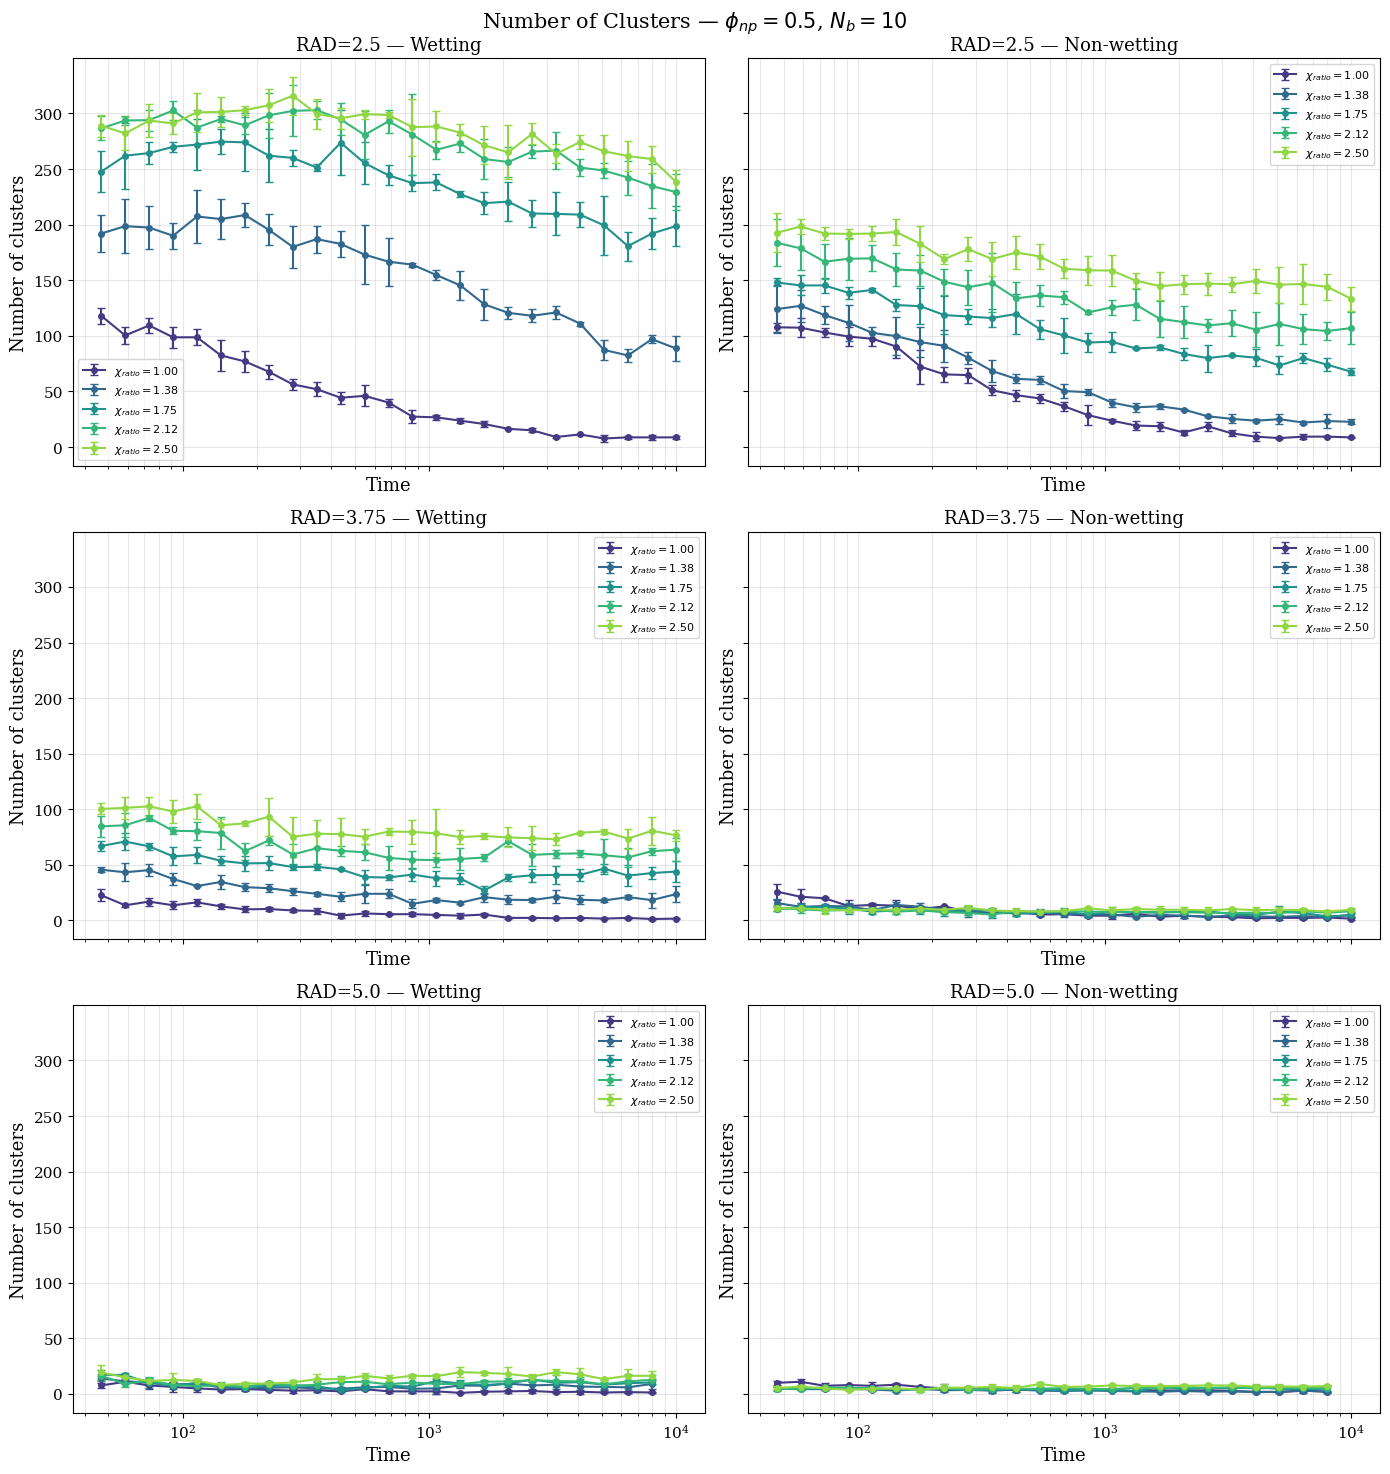

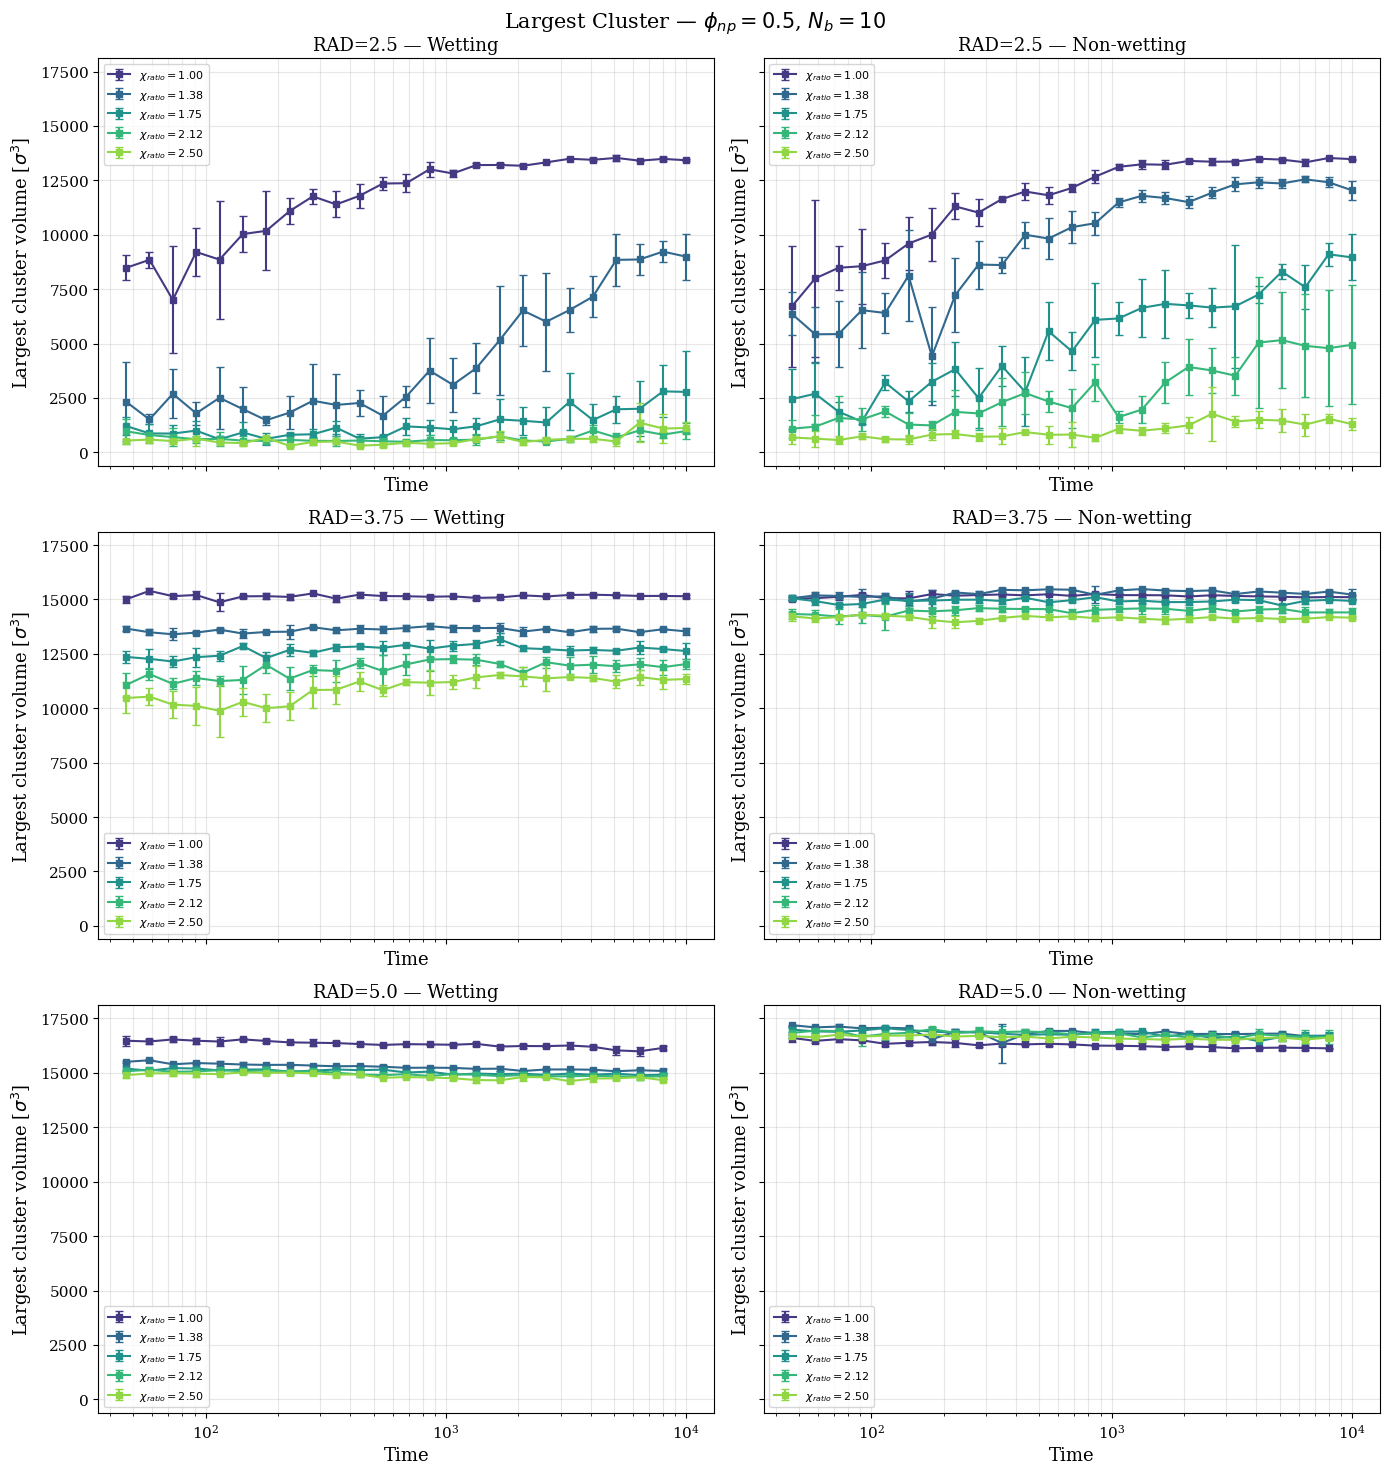

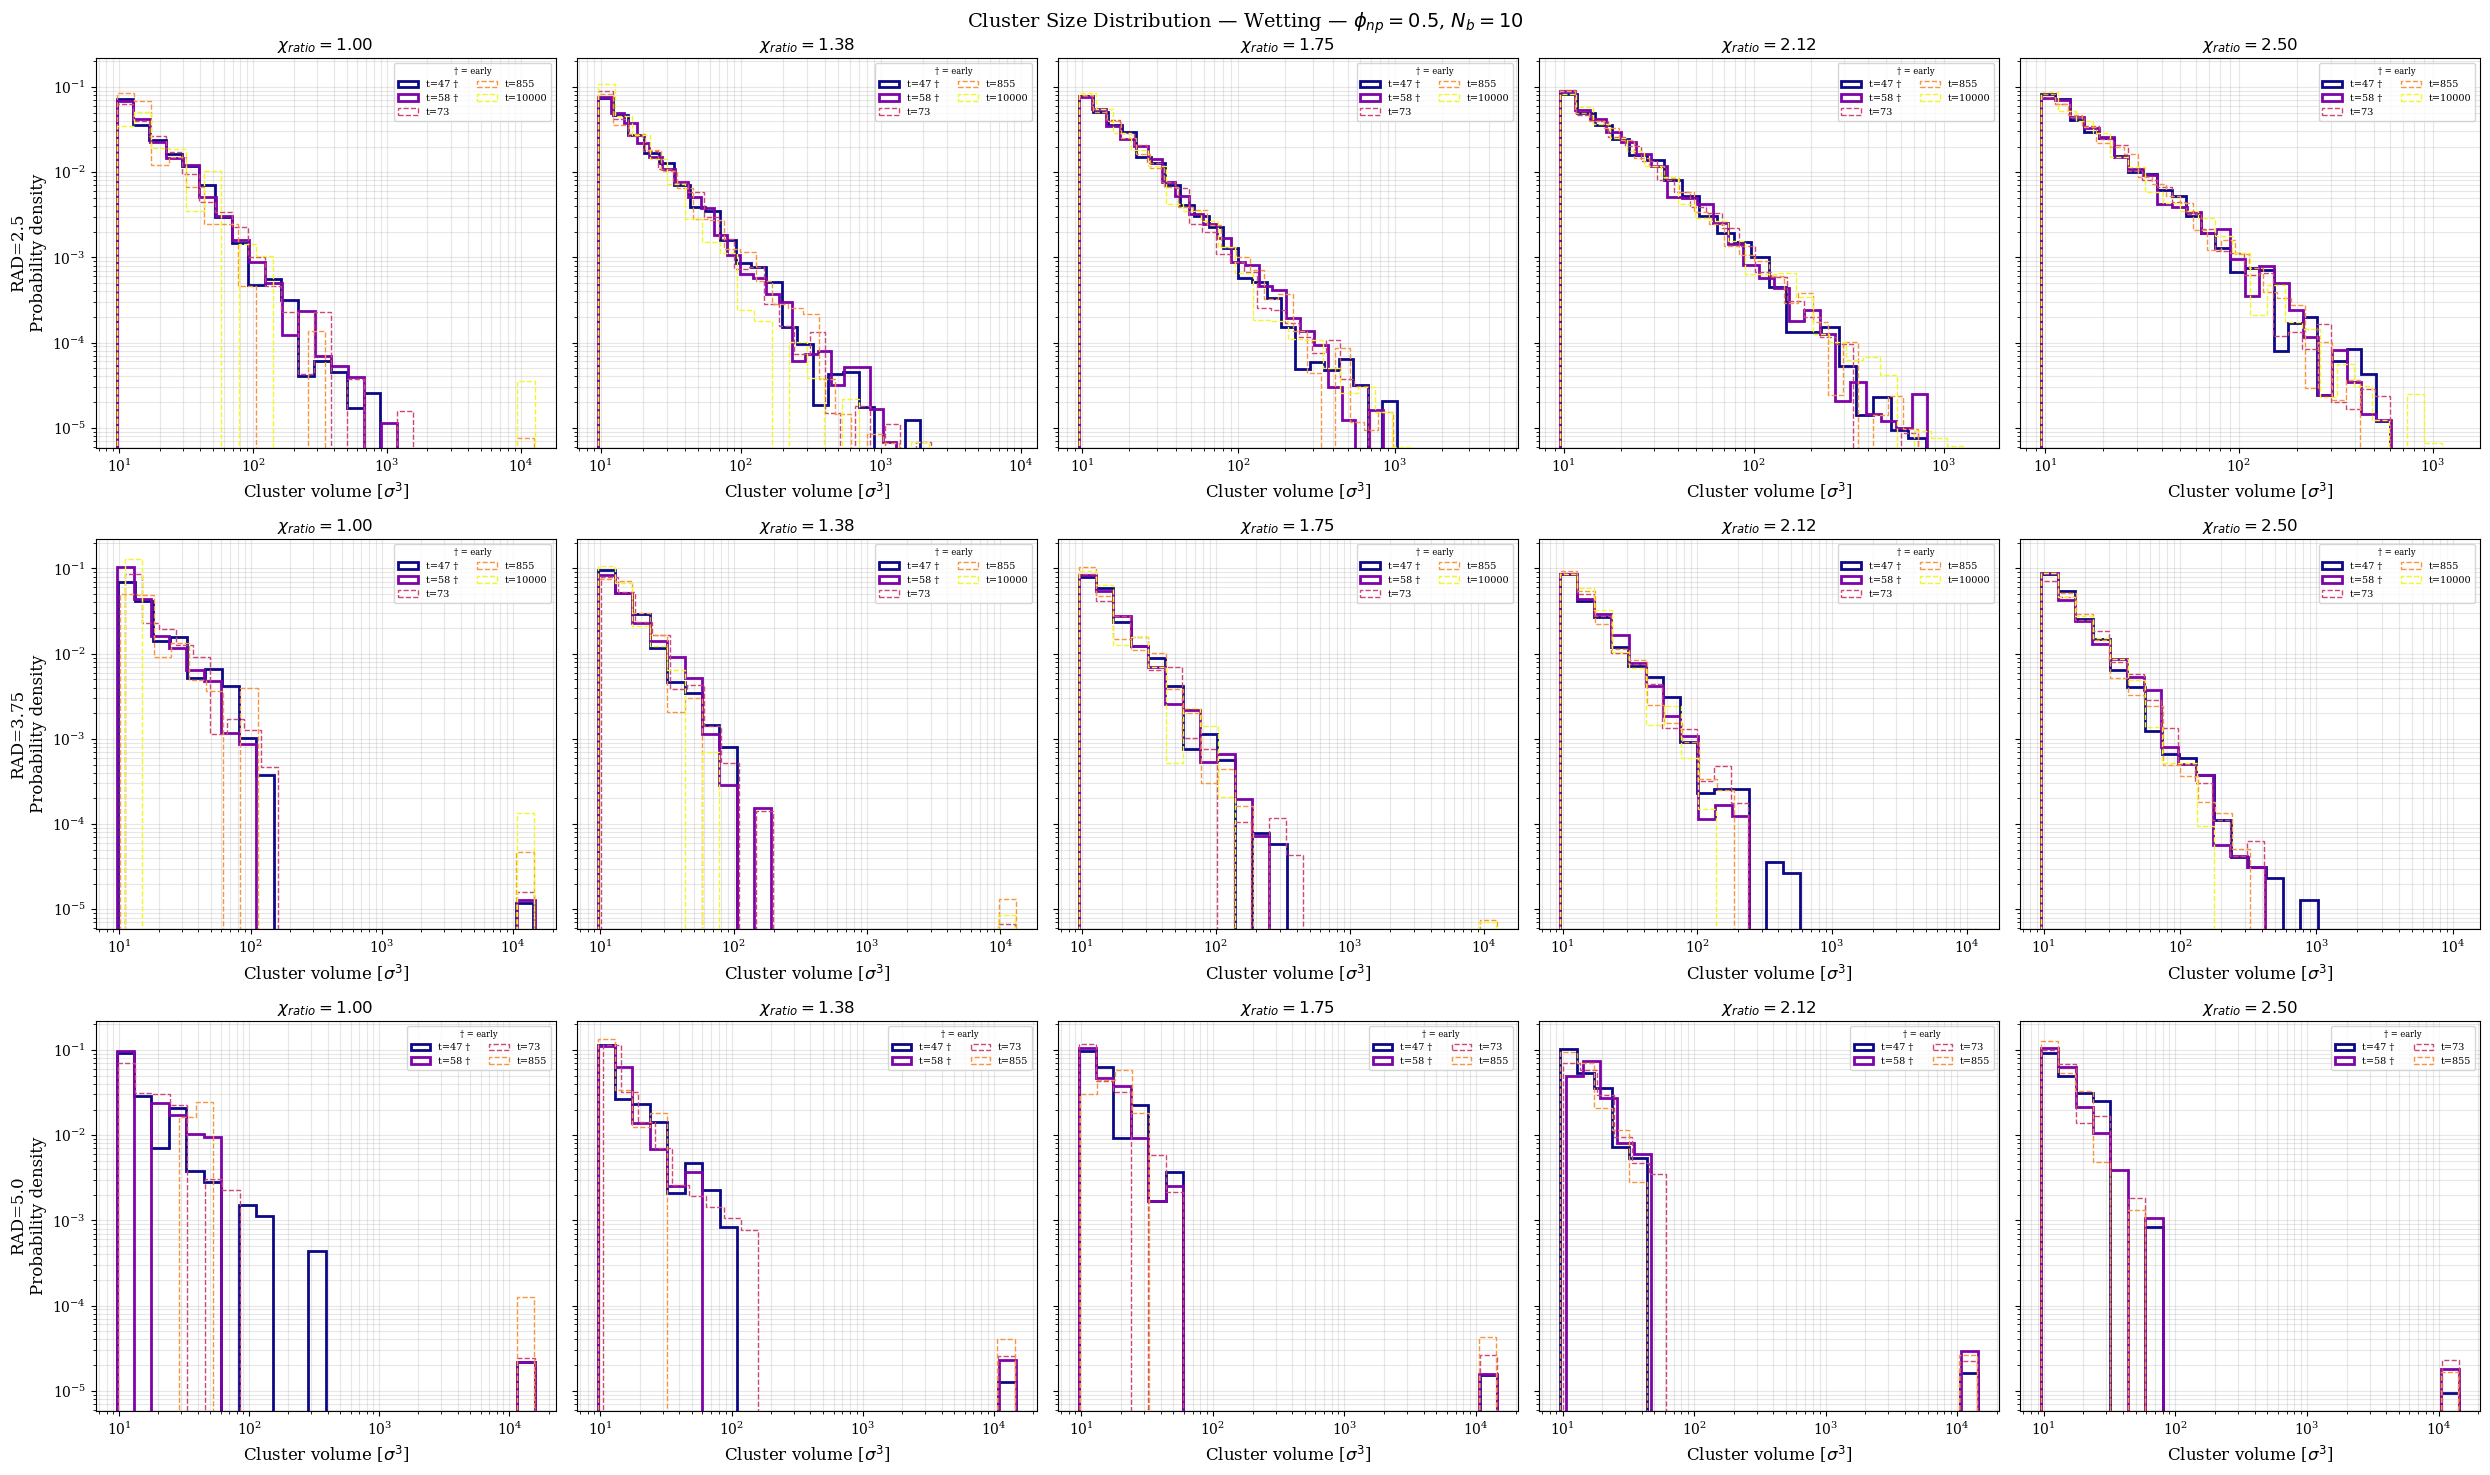

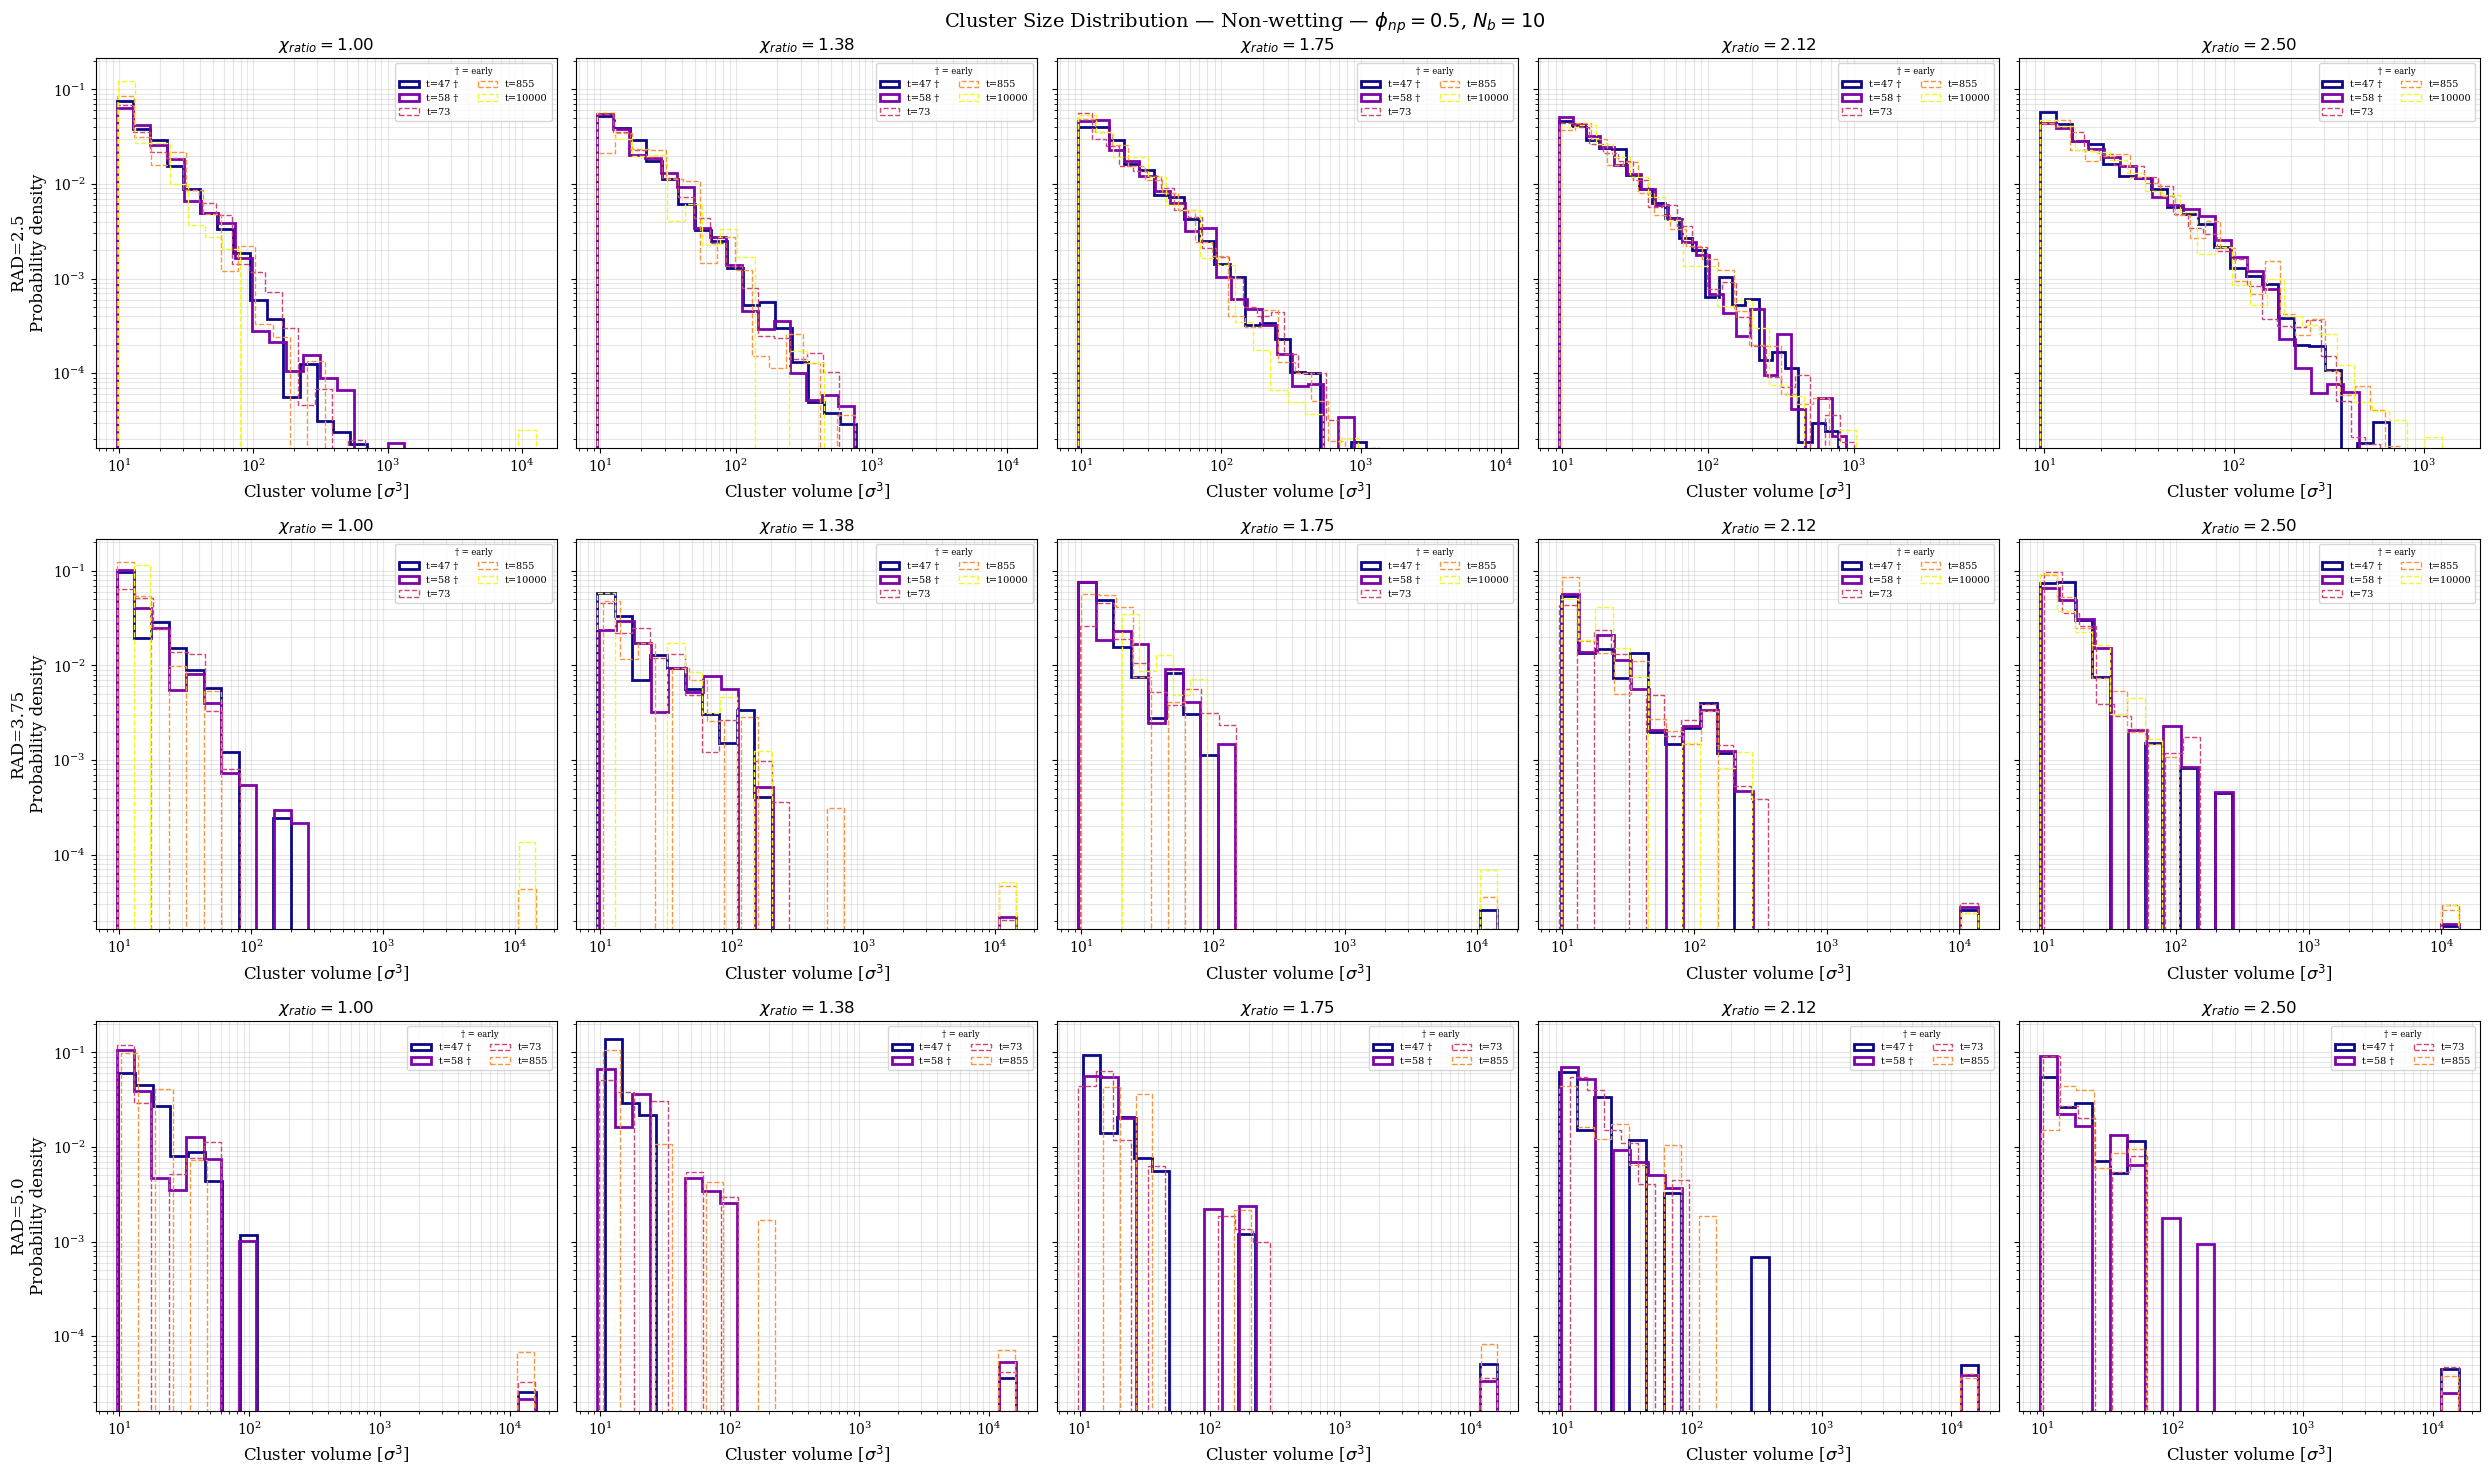

In [12]:
# Plot cluster analysis results
# Layout: figure per (phi_np, Nb); rows = radii; cols = polymer type.

from collections import defaultdict

poly_labels  = {0: 'Wetting', 1: 'Non-wetting'}

pot_list_cl      = sorted(cluster_df['POT'].unique(), key=float)
pot_colors_cl    = sns.color_palette('viridis', len(pot_list_cl))
pot_color_map_cl = dict(zip(pot_list_cl, pot_colors_cl))

rads_cl = sorted(cluster_df['rad'].unique(), key=float)
n_rads  = len(rads_cl)

# ── 1. Number of clusters vs time ─────────────────────────────────────────────
for (phi_np, nb), sub_df in cluster_df.groupby(['phi_np', 'Nb']):
    fig, axes = plt.subplots(n_rads, 2, figsize=(14, 5 * n_rads),
                             sharey=True, sharex=True)
    if n_rads == 1:
        axes = [axes]

    for row, rad in enumerate(rads_cl):
        rad_df = sub_df[sub_df['rad'] == rad]

        for col, poly_type in enumerate([0, 1]):
            ax   = axes[row][col]
            pt_df = rad_df[rad_df['poly_type'] == poly_type]

            for pot, pot_df in pt_df.groupby('POT'):
                stats = pot_df.groupby('time')['n_clusters'].agg(['mean', 'std']).reset_index()
                chi   = float(pot) / 10.0
                ax.errorbar(stats['time'], stats['mean'], yerr=stats['std'],
                            marker='o', ms=4, color=pot_color_map_cl[pot], capsize=3,
                            label=rf'$\chi_{{ratio}}={chi:.2f}$')

            ax.set_xscale('log')
            ax.set_xlabel('Time', fontsize=13)
            ax.set_ylabel('Number of clusters', fontsize=13)
            ax.set_title(f'RAD={rad} — {poly_labels[poly_type]}', fontsize=13)
            ax.legend(fontsize=8, frameon=True)
            ax.tick_params(labelsize=11)
            ax.grid(alpha=0.3, which='both')

    fig.suptitle(rf'Number of Clusters — $\phi_{{np}}={phi_np}$, $N_b={nb}$', fontsize=15)
    fig.tight_layout()
    plt.show()

# ── 2. Largest cluster volume vs time ─────────────────────────────────────────
for (phi_np, nb), sub_df in cluster_df.groupby(['phi_np', 'Nb']):
    fig, axes = plt.subplots(n_rads, 2, figsize=(14, 5 * n_rads),
                             sharey=True, sharex=True)
    if n_rads == 1:
        axes = [axes]

    for row, rad in enumerate(rads_cl):
        rad_df = sub_df[sub_df['rad'] == rad]

        for col, poly_type in enumerate([0, 1]):
            ax    = axes[row][col]
            pt_df = rad_df[rad_df['poly_type'] == poly_type]

            for pot, pot_df in pt_df.groupby('POT'):
                stats = pot_df.groupby('time')['largest_cluster'].agg(['mean', 'std']).reset_index()
                chi   = float(pot) / 10.0
                ax.errorbar(stats['time'], stats['mean'], yerr=stats['std'],
                            marker='s', ms=4, color=pot_color_map_cl[pot], capsize=3,
                            label=rf'$\chi_{{ratio}}={chi:.2f}$')

            ax.set_xscale('log')
            ax.set_xlabel('Time', fontsize=13)
            ax.set_ylabel(r'Largest cluster volume [$\sigma^3$]', fontsize=13)
            ax.set_title(f'RAD={rad} — {poly_labels[poly_type]}', fontsize=13)
            ax.legend(fontsize=8, frameon=True)
            ax.tick_params(labelsize=11)
            ax.grid(alpha=0.3, which='both')

    fig.suptitle(rf'Largest Cluster — $\phi_{{np}}={phi_np}$, $N_b={nb}$', fontsize=15)
    fig.tight_layout()
    plt.show()

# ── 3. Cluster size distribution over time ────────────────────────────────────
all_frame_ids = sorted(cluster_df['frame'].unique())
early_frames  = [f for f in all_frame_ids if f <= 10]
late_frames   = [f for f in all_frame_ids if f > 10]

if len(early_frames) >= 3:
    mid_e = len(early_frames) // 2
    selected_early = [early_frames[0], early_frames[mid_e], early_frames[-1]]
else:
    selected_early = early_frames

if len(late_frames) >= 3:
    idxs = [0, len(late_frames) // 2, len(late_frames) - 1]
    selected_late = [late_frames[i] for i in idxs]
elif late_frames:
    selected_late = late_frames
else:
    selected_late = []

selected_frames = sorted(set(selected_early + selected_late))
n_sel        = len(selected_frames)
frame_cmap   = plt.cm.plasma
frame_colors = {f: frame_cmap(i / max(n_sel - 1, 1))
                for i, f in enumerate(selected_frames)}

dx_cl     = float(L_BOX) / 81.0
voxel_vol = dx_cl ** 3

for (phi_np, nb), sub_df in cluster_df.groupby(['phi_np', 'Nb']):
    for poly_type in [0, 1]:
        pt_df = sub_df[sub_df['poly_type'] == poly_type]

        # rows = radii, cols = POTs
        pots   = sorted(pt_df['POT'].unique(), key=float)
        n_pots = len(pots)

        fig, axes = plt.subplots(n_rads, n_pots,
                                 figsize=(5 * n_pots, 5 * n_rads),
                                 sharey=True)
        if n_rads == 1:
            axes = [axes]
        if n_pots == 1:
            axes = [[row] for row in axes]

        for row, rad in enumerate(rads_cl):
            rad_df = pt_df[pt_df['rad'] == rad]

            for col, pot in enumerate(pots):
                ax     = axes[row][col]
                chi    = float(pot) / 10.0
                pot_df = rad_df[rad_df['POT'] == pot]

                for f_idx in selected_frames:
                    frame_df = pot_df[pot_df['frame'] == f_idx]
                    if frame_df.empty:
                        continue

                    all_vols = np.concatenate([
                        row_r['sizes_voxels'] * voxel_vol
                        for _, row_r in frame_df.iterrows()
                        if len(row_r['sizes_voxels']) > 0
                    ])
                    if len(all_vols) == 0:
                        continue

                    v_min, v_max = all_vols.min(), all_vols.max()
                    if v_min >= v_max:
                        continue

                    bins     = np.logspace(np.log10(v_min), np.log10(v_max), 25)
                    time_val = frame_df['time'].iloc[0]
                    is_early = f_idx <= 10
                    ax.hist(all_vols, bins=bins, density=True, histtype='step',
                            color=frame_colors[f_idx],
                            lw=2.0 if is_early else 1.0,
                            linestyle='-' if is_early else '--',
                            label=f't={time_val:.0f}' + (' †' if is_early else ''))

                ax.set_xscale('log')
                ax.set_yscale('log')
                ax.set_xlabel(r'Cluster volume [$\sigma^3$]', fontsize=12)
                if col == 0:
                    ax.set_ylabel(f'RAD={rad}\nProbability density', fontsize=12)
                ax.set_title(rf'$\chi_{{ratio}}={chi:.2f}$', fontsize=12)
                ax.legend(fontsize=7, frameon=True, ncol=2,
                          title='† = early', title_fontsize=6)
                ax.tick_params(labelsize=10)
                ax.grid(alpha=0.3, which='both')

        fig.suptitle(
            rf'Cluster Size Distribution — {poly_labels[poly_type]} — '
            rf'$\phi_{{np}}={phi_np}$, $N_b={nb}$',
            fontsize=14
        )
        fig.tight_layout()
        plt.show()


In [ ]:
# Compute cluster statistics — symmetric reset runs

sym_reset_cl_pattern = re.compile(
    r"^sym_reset_PS_in_NP_frac_([\d.]+)_rad_([\d.]+)_POT_([\d.]+)_Nb_(\d+)_rep_(\d+)_densities\.bin$"
)


def _process_cluster_file_symreset(args):
    """Worker: cluster analysis for one sym_reset density file.

    Uses a per-file log-step schedule so the last frame is correctly
    labelled as step ≈ max_steps regardless of n_file_frames.
    skip=0 because sym_reset starts from an already-equilibrated state.
    """
    fpath, phi_np, rad, pot, nb, rep, max_steps_w, freq_w = args

    Nx_arr, L_arr, ntypes, rho_frames = read_density_all_frames(fpath)
    n_file_frames = len(rho_frames)
    file_steps = calculate_log_steps(max_steps_w, n_file_frames, freq_w)

    dx = L_arr[0] / Nx_arr[0]
    voxel_vol = dx**3
    min_size_voxels = math.ceil(int(nb) / voxel_vol)

    file_results = []
    for frame_idx in range(n_file_frames):
        rho = rho_frames[frame_idx]
        step = file_steps[frame_idx]
        time_val = step * 0.005

        for target_type in [0, 1]:
            _, sizes, _ = cluster_density_field(rho[0], rho[1], target_type)
            sizes = sizes[sizes >= min_size_voxels]
            n_clust = len(sizes)

            file_results.append({
                'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
                'poly_type': target_type, 'frame': frame_idx,
                'step': step, 'time': time_val,
                'n_clusters': n_clust,
                'largest_cluster': sizes[0] * voxel_vol if n_clust > 0 else 0.0,
                'mean_cluster_size': sizes.mean() * voxel_vol if n_clust > 0 else 0.0,
                'sizes_voxels': sizes,
            })
    print(f"  Done: {os.path.basename(fpath)}")
    return file_results


# Build task list from the same density_directory used by standard cluster cell
sym_cl_tasks = []
for subfolder in sorted(os.listdir(density_directory)):
    sub_path = os.path.join(density_directory, subfolder)
    if not os.path.isdir(sub_path):
        continue
    for fname in sorted(os.listdir(sub_path)):
        m = sym_reset_cl_pattern.match(fname)
        if not m:
            continue
        phi_np, rad, pot, nb, rep = m.groups()
        fpath = os.path.join(sub_path, fname)
        sym_cl_tasks.append((fpath, phi_np, rad, pot, nb, rep, max_steps, freq))

print(f"Found {len(sym_cl_tasks)} sym_reset density files for cluster analysis")

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
sym_cl_hits, sym_cl_miss_tasks, sym_cl_miss_cps = [], [], []
for task in sym_cl_tasks:
    fpath_t, phi_np_t, rad_t, pot_t, nb_t, rep_t, *_ = task
    cp = _cache_path('cluster', phi_np_t, rad_t, pot_t, nb_t, rep_t, 'sym_reset')
    if not FORCE_RECOMPUTE and cp.exists():
        sym_cl_hits.extend(_load_pkl(cp))
    else:
        sym_cl_miss_tasks.append(task)
        sym_cl_miss_cps.append(cp)

n_sym_cached = len(sym_cl_tasks) - len(sym_cl_miss_tasks)
print(f"[cache] {n_sym_cached} loaded, {len(sym_cl_miss_tasks)} to compute")

if sym_cl_miss_tasks:
    n_workers = choose_n_workers(len(sym_cl_miss_tasks))
    with Pool(n_workers) as pool:
        new_results = pool.map(_process_cluster_file_symreset, sym_cl_miss_tasks)
    for file_res, cp in zip(new_results, sym_cl_miss_cps):
        _save_pkl(file_res, cp)
        sym_cl_hits.extend(file_res)

cluster_sym_df = pd.DataFrame(sym_cl_hits)
cluster_sym_df['chi_ratio'] = cluster_sym_df['POT'].astype(float) / 10.0
print(f"\nTotal sym_reset cluster rows: {len(cluster_sym_df)}")
print(f"  POT:  {sorted(cluster_sym_df['POT'].unique())}")
print(f"  rad:  {sorted(cluster_sym_df['rad'].unique())}")
print(f"  last step: {cluster_sym_df['step'].max()}")


In [ ]:
# IC Comparison — cluster statistics: standard vs symmetric reset (rad=5.0 only)
# sym_reset files exist only for rad=5.0, so both datasets are filtered to rad=5.0.
# Only chi_ratio > 1.0 systems are shown.

cluster_df_std = cluster_df.copy()
cluster_df_std['init'] = 'standard'

cluster_sym_df_plot = cluster_sym_df.copy()
cluster_sym_df_plot['init'] = 'sym_reset'

cluster_comb = pd.concat([cluster_df_std, cluster_sym_df_plot], ignore_index=True)
cluster_comb = cluster_comb[
    (cluster_comb['rad'] == '5.0') &
    (cluster_comb['chi_ratio'] > 1.0)
]

init_styles_cl = {
    'standard':  ('-',  'Standard IC'),
    'sym_reset': ('--', 'Sym. reset IC'),
}

pot_list_clic   = sorted(cluster_comb['POT'].unique(), key=float)
cl_colors_clic  = sns.color_palette('viridis', len(pot_list_clic))
cl_color_map    = dict(zip(pot_list_clic, cl_colors_clic))
poly_labels_cl  = {0: 'Wetting', 1: 'Non-wetting'}

for (phi_np, nb), sub_df in cluster_comb.groupby(['phi_np', 'Nb']):
    for poly_type in [0, 1]:
        pt_df = sub_df[sub_df['poly_type'] == poly_type]
        if pt_df.empty:
            continue

        fig, axes = plt.subplots(1, 2, figsize=(14, 5))

        for pot, pot_df in pt_df.groupby('POT'):
            color = cl_color_map[pot]
            chi   = float(pot) / 10.0

            for init_type, (ls, lbl_init) in init_styles_cl.items():
                init_df = pot_df[pot_df['init'] == init_type]
                if init_df.empty:
                    continue

                stats_n = init_df.groupby('time')['n_clusters'].agg(['mean', 'std']).reset_index()
                stats_l = init_df.groupby('time')['largest_cluster'].agg(['mean', 'std']).reset_index()

                lbl = rf'$\chi_{{ratio}}={chi:.2f}$, {lbl_init}'

                axes[0].errorbar(stats_n['time'], stats_n['mean'], yerr=stats_n['std'],
                                 fmt='o-', ms=3, color=color, linestyle=ls,
                                 capsize=2, linewidth=1.5, label=lbl)
                axes[1].errorbar(stats_l['time'], stats_l['mean'], yerr=stats_l['std'],
                                 fmt='s-', ms=3, color=color, linestyle=ls,
                                 capsize=2, linewidth=1.5, label=lbl)

        for ax, ylabel in zip(axes,
                              ['Number of clusters',
                               r'Largest cluster [$\sigma^3$]']):
            ax.set_xscale('log')
            ax.set_xlabel('Time', fontsize=13)
            ax.set_ylabel(ylabel, fontsize=13)
            ax.legend(fontsize=7, frameon=True, ncol=2)
            ax.grid(alpha=0.3, which='both')
            ax.tick_params(labelsize=11)

        fig.suptitle(
            rf'Cluster IC Comparison ({poly_labels_cl[poly_type]}) — '
            rf'$\phi_{{np}}={phi_np}$, $N_b={nb}$, RAD=5.0',
            fontsize=13
        )
        fig.tight_layout()
        plt.show()


In [13]:
# Interfacial Area — Gradient Method (compute)
#
# A_int = integral |grad(f_wet)| dV,  f_wet = rho_0 / (rho_0 + rho_1)
# Spectral (FFT) gradient for periodic boundaries.
# Processes both standard and sym_reset density files.

from multiprocessing import Pool
import re


def _process_interface_file(args):
    """
    Worker: compute interfacial area A_int (gradient method) for every frame.

    Uses FFT-based spectral gradient of the wetting number fraction f_wet.
    Only polymer-rich voxels (rho_0 + rho_1 > 0.05) contribute.
    """
    fpath, phi_np, rad, pot, nb, rep, init, steps = args

    Nx_arr, L_arr, ntypes, rho_frames = read_density_all_frames(fpath)
    dx = float(L_arr[0]) / float(Nx_arr[0])
    voxel_vol = dx ** 3

    # Wavenumber arrays — shape matches (Nz, Ny, Nx)
    axes = [np.fft.fftfreq(int(Nx_arr[d]), d=1.0) * 2.0 * np.pi / float(L_arr[d])
            for d in range(len(Nx_arr))]
    kz, ky, kx = np.meshgrid(axes[2], axes[1], axes[0], indexing='ij')

    eps = 1e-6
    file_results = []

    for frame_idx, rho in enumerate(rho_frames):
        step     = steps[frame_idx] if frame_idx < len(steps) else frame_idx
        time_val = step * 0.005

        rho_0 = rho[0].astype(np.float64)
        rho_1 = rho[1].astype(np.float64)
        total  = rho_0 + rho_1

        f_wet = rho_0 / (total + eps)
        F     = np.fft.fftn(f_wet)

        gx = np.real(np.fft.ifftn(1j * kx * F))
        gy = np.real(np.fft.ifftn(1j * ky * F))
        gz = np.real(np.fft.ifftn(1j * kz * F))
        grad_mag = np.sqrt(gx**2 + gy**2 + gz**2)

        poly_mask = total > 0.05
        A_int = float(np.sum(grad_mag * poly_mask) * voxel_vol)

        file_results.append({
            'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
            'init': init,
            'frame': frame_idx, 'step': step, 'time': time_val,
            'A_int': A_int,
        })

    print(f"  Done: {os.path.basename(fpath)}")
    return file_results


# Build task list — standard runs
iface_tasks = []
for subfolder in sorted(os.listdir(density_directory)):
    sub_path = os.path.join(density_directory, subfolder)
    if not os.path.isdir(sub_path):
        continue
    for fname in sorted(os.listdir(sub_path)):
        m = density_pattern.match(fname)
        if m:
            phi_np, rad, pot, nb, rep = m.groups()
            iface_tasks.append((os.path.join(sub_path, fname),
                                phi_np, rad, pot, nb, rep, 'standard', steps))
        else:
            # Interfacial Area — Gradient Method (compute)
            #
            # A_int = integral |grad(f_wet)| dV,  f_wet = rho_0 / (rho_0 + rho_1)
            # Spectral (FFT) gradient for periodic boundaries.
            # Processes both standard and sym_reset density files.


            # Define regex patterns for file matching
            density_pattern = re.compile(r'PS_in_NP_frac_(\d+\.\d+)_rad_(\d+\.\d+)_POT_(\d+\.\d+)_Nb_(\d+)_rep_(\d+)_densities\.bin')
            sym_reset_pattern = re.compile(r'sym_reset_PS_in_NP_frac_(\d+\.\d+)_rad_(\d+\.\d+)_POT_(\d+\.\d+)_Nb_(\d+)_rep_(\d+)_densities\.bin')

            def _process_interface_file(args):
                """
                Worker: compute interfacial area A_int (gradient method) for every frame.

                Uses FFT-based spectral gradient of the wetting number fraction f_wet.
                Only polymer-rich voxels (rho_0 + rho_1 > 0.05) contribute.
                """
                fpath, phi_np, rad, pot, nb, rep, init, steps = args

                Nx_arr, L_arr, ntypes, rho_frames = read_density_all_frames(fpath)
                dx = float(L_arr[0]) / float(Nx_arr[0])
                voxel_vol = dx ** 3

                # Wavenumber arrays — shape matches (Nz, Ny, Nx)
                axes = [np.fft.fftfreq(int(Nx_arr[d]), d=1.0) * 2.0 * np.pi / float(L_arr[d])
                        for d in range(len(Nx_arr))]
                kz, ky, kx = np.meshgrid(axes[2], axes[1], axes[0], indexing='ij')

                eps = 1e-6
                file_results = []

                for frame_idx, rho in enumerate(rho_frames):
                    step     = steps[frame_idx] if frame_idx < len(steps) else frame_idx
                    time_val = step * 0.005

                    rho_0 = rho[0].astype(np.float64)
                    rho_1 = rho[1].astype(np.float64)
                    total  = rho_0 + rho_1

                    f_wet = rho_0 / (total + eps)
                    F     = np.fft.fftn(f_wet)

                    gx = np.real(np.fft.ifftn(1j * kx * F))
                    gy = np.real(np.fft.ifftn(1j * ky * F))
                    gz = np.real(np.fft.ifftn(1j * kz * F))
                    grad_mag = np.sqrt(gx**2 + gy**2 + gz**2)

                    poly_mask = total > 0.05
                    A_int = float(np.sum(grad_mag * poly_mask) * voxel_vol)

                    file_results.append({
                        'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
                        'init': init,
                        'frame': frame_idx, 'step': step, 'time': time_val,
                        'A_int': A_int,
                    })

                print(f"  Done: {os.path.basename(fpath)}")
                return file_results


            # Build task list — standard runs
            iface_tasks = []
            for subfolder in sorted(os.listdir(density_directory)):
                sub_path = os.path.join(density_directory, subfolder)
                if not os.path.isdir(sub_path):
                    continue
                for fname in sorted(os.listdir(sub_path)):
                    m = density_pattern.match(fname)
                    if m:
                        phi_np, rad, pot, nb, rep = m.groups()
                        iface_tasks.append((os.path.join(sub_path, fname),
                                            phi_np, rad, pot, nb, rep, 'standard', steps))
                    else:
                        m2 = sym_reset_pattern.match(fname)
                        if m2:
                            phi_np, rad, pot, nb, rep = m2.groups()
                            iface_tasks.append((os.path.join(sub_path, fname),
                                                phi_np, rad, pot, nb, rep, 'sym_reset', steps))

            # ── Cache-aware dispatch ──────────────────────────────────────────────────────
            hit_results, miss_tasks, miss_cps = [], [], []

            for task in iface_tasks:
                fpath_t, phi_np_t, rad_t, pot_t, nb_t, rep_t, init_t, steps_t = task
                cp = _cache_path('iface_grad', phi_np_t, rad_t, pot_t, nb_t, rep_t, init_t)
                if not FORCE_RECOMPUTE and cp.exists():
                    hit_results.extend(_load_pkl(cp))
                else:
                    miss_tasks.append(task)
                    miss_cps.append(cp)

            n_cached = len(iface_tasks) - len(miss_tasks)
            if miss_tasks:
                n_workers = choose_n_workers(len(miss_tasks))
                print(f"Computing {len(miss_tasks)} files with {n_workers} workers (gradient method)")
                with Pool(n_workers) as pool:
                    new_results = pool.map(_process_interface_file, miss_tasks)
                for file_res, cp in zip(new_results, miss_cps):
                    _save_pkl(file_res, cp)
                    hit_results.extend(file_res)

            print(f"[cache] {n_cached} loaded, {len(miss_tasks)} computed")
            iface_results = hit_results
            print(f"\nTotal (file × frame) interfacial areas: {len(iface_results)}")
            iface_df = pd.DataFrame(iface_results)
            iface_df['chi_ratio'] = iface_df['POT'].astype(float) / 10.0
            if m2:
                phi_np, rad, pot, nb, rep = m2.groups()
                iface_tasks.append((os.path.join(sub_path, fname),
                                    phi_np, rad, pot, nb, rep, 'sym_reset', steps))

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
hit_results, miss_tasks, miss_cps = [], [], []

for task in iface_tasks:
    fpath_t, phi_np_t, rad_t, pot_t, nb_t, rep_t, init_t, steps_t = task
    cp = _cache_path('iface_grad', phi_np_t, rad_t, pot_t, nb_t, rep_t, init_t)
    if not FORCE_RECOMPUTE and cp.exists():
        hit_results.extend(_load_pkl(cp))
    else:
        miss_tasks.append(task)
        miss_cps.append(cp)

n_cached = len(iface_tasks) - len(miss_tasks)
if miss_tasks:
    n_workers = choose_n_workers(len(miss_tasks))
    print(f"Computing {len(miss_tasks)} files with {n_workers} workers (gradient method)")
    with Pool(n_workers) as pool:
        new_results = pool.map(_process_interface_file, miss_tasks)
    for file_res, cp in zip(new_results, miss_cps):
        _save_pkl(file_res, cp)
        hit_results.extend(file_res)

print(f"[cache] {n_cached} loaded, {len(miss_tasks)} computed")
iface_results = hit_results
print(f"\nTotal (file × frame) interfacial areas: {len(iface_results)}")
iface_df = pd.DataFrame(iface_results)
iface_df['chi_ratio'] = iface_df['POT'].astype(float) / 10.0


[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 loaded, 0 computed

Total (file × frame) interfacial areas: 1911
[cache] 57 l

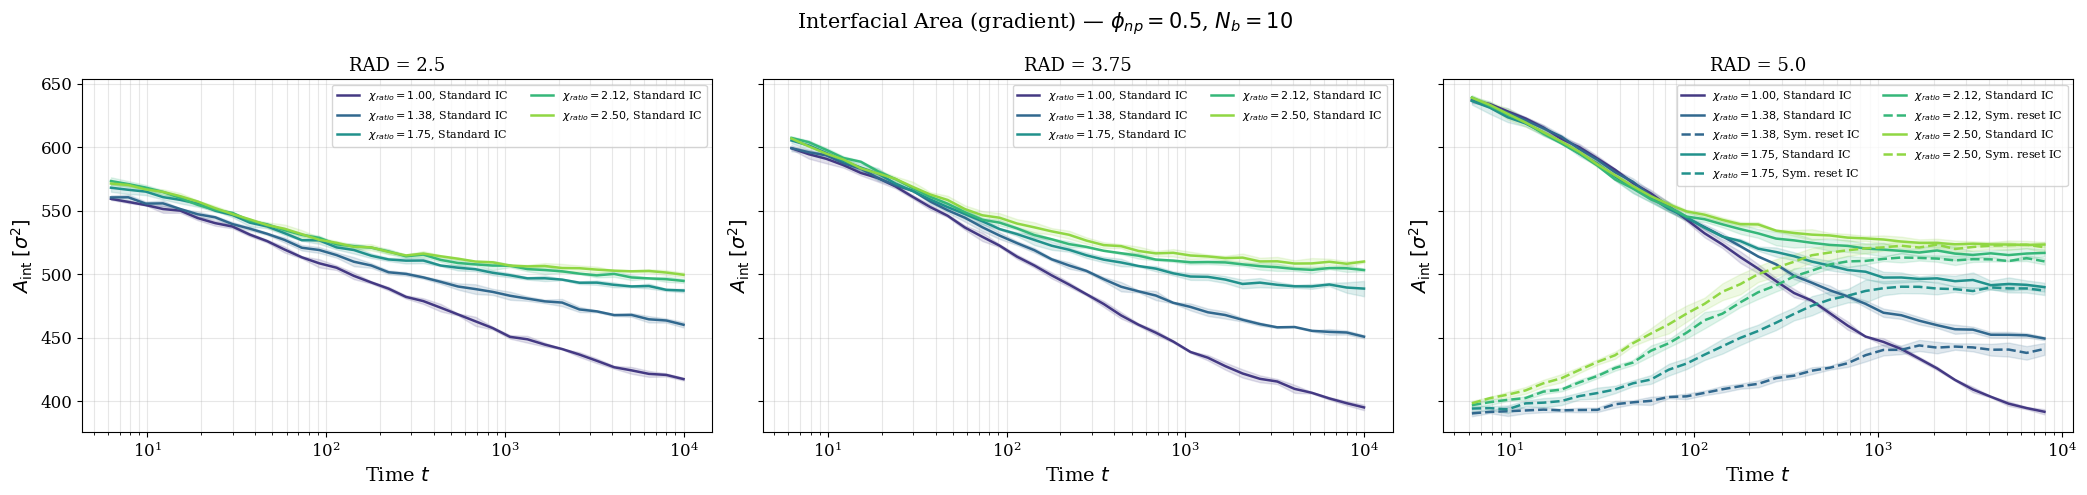

In [14]:
# Interfacial Area — Gradient Method (plot)
# Figure per (phi_np, Nb); columns = radii; all 5 POTs as curves.
# Solid = standard IC; dashed = sym_reset IC. Shaded = ±1 std over replicas.

init_styles = {
    'standard':  ('-',  'Standard IC'),
    'sym_reset': ('--', 'Sym. reset IC'),
}

pot_list_if      = sorted(iface_df['POT'].unique(), key=float)
pot_colors_if    = sns.color_palette('viridis', len(pot_list_if))
pot_color_map_if = dict(zip(pot_list_if, pot_colors_if))

rads_if = sorted(iface_df['rad'].unique(), key=float)

for (phi_np, nb), sub_df in iface_df.groupby(['phi_np', 'Nb']):
    fig, axes = plt.subplots(1, len(rads_if),
                             figsize=(7 * len(rads_if), 5),
                             sharey=True, squeeze=False)

    for col, rad in enumerate(rads_if):
        ax     = axes[0][col]
        rad_df = sub_df[sub_df['rad'] == rad]

        for pot in pot_list_if:
            chi   = float(pot) / 10.0
            color = pot_color_map_if[pot]

            for init, (ls, init_lbl) in init_styles.items():
                g = rad_df[(rad_df['POT'] == pot) & (rad_df['init'] == init)]
                if g.empty:
                    continue
                stats = g.groupby('time')['A_int'].agg(['mean', 'std']).reset_index()
                ax.plot(stats['time'], stats['mean'],
                        color=color, lw=1.8, ls=ls,
                        label=rf'$\chi_{{ratio}}={chi:.2f}$, {init_lbl}')
                ax.fill_between(stats['time'],
                                stats['mean'] - stats['std'],
                                stats['mean'] + stats['std'],
                                color=color, alpha=0.15)

        ax.set_xscale('log')
        ax.set_xlabel(r'Time $t$', fontsize=14)
        ax.set_ylabel(r'$A_\mathrm{int}\;[\sigma^2]$', fontsize=14)
        ax.set_title(f'RAD = {rad}', fontsize=13)
        ax.legend(fontsize=8, frameon=True, ncol=2)
        ax.tick_params(labelsize=12)
        ax.grid(alpha=0.3, which='both')

    fig.suptitle(
        rf'Interfacial Area (gradient) — $\phi_{{np}}={phi_np}$, $N_b={nb}$',
        fontsize=15
    )
    fig.tight_layout()
    plt.show()


In [15]:
# Interfacial Area — Inner Product Method (compute)
#
# A_int_ip = integral rho_0(r) * rho_1(r) dV
#
# Rationale: the product rho_0 * rho_1 is large only where both polymer species
# coexist, i.e. at the interface.  In a fully phase-separated system the two
# density fields are spatially exclusive and the integral vanishes; in a mixed
# system it is maximised.  Unlike the gradient method this measure does not
# require a gradient calculation and carries units of (density^2 * volume).
# Both standard and sym_reset runs are processed.

from multiprocessing import Pool


def _process_interface_ip_file(args):
    """
    Worker: compute inner-product interfacial area for every frame.
    """
    fpath, phi_np, rad, pot, nb, rep, init, steps = args

    Nx_arr, L_arr, ntypes, rho_frames = read_density_all_frames(fpath)
    dx = float(L_arr[0]) / float(Nx_arr[0])
    voxel_vol = dx ** 3

    file_results = []

    for frame_idx, rho in enumerate(rho_frames):
        step     = steps[frame_idx] if frame_idx < len(steps) else frame_idx
        time_val = step * 0.005

        rho_0 = rho[0].astype(np.float64)
        rho_1 = rho[1].astype(np.float64)

        A_int_ip = float(np.sum(rho_0 * rho_1) * voxel_vol)

        file_results.append({
            'phi_np': phi_np, 'rad': rad, 'POT': pot, 'Nb': nb, 'rep': rep,
            'init': init,
            'frame': frame_idx, 'step': step, 'time': time_val,
            'A_int_ip': A_int_ip,
        })

    print(f"  Done: {os.path.basename(fpath)}")
    return file_results


# Build task list — reuse directory/patterns from cluster cell
iface_ip_tasks = []
for subfolder in sorted(os.listdir(density_directory)):
    sub_path = os.path.join(density_directory, subfolder)
    if not os.path.isdir(sub_path):
        continue
    for fname in sorted(os.listdir(sub_path)):
        m = density_pattern.match(fname)
        if m:
            phi_np, rad, pot, nb, rep = m.groups()
            iface_ip_tasks.append((os.path.join(sub_path, fname),
                                   phi_np, rad, pot, nb, rep, 'standard', steps))
        else:
            m2 = sym_reset_pattern.match(fname)
            if m2:
                phi_np, rad, pot, nb, rep = m2.groups()
                iface_ip_tasks.append((os.path.join(sub_path, fname),
                                       phi_np, rad, pot, nb, rep, 'sym_reset', steps))

# ── Cache-aware dispatch ──────────────────────────────────────────────────────
hit_results, miss_tasks, miss_cps = [], [], []

for task in iface_ip_tasks:
    fpath_t, phi_np_t, rad_t, pot_t, nb_t, rep_t, init_t, steps_t = task
    cp = _cache_path('iface_ip', phi_np_t, rad_t, pot_t, nb_t, rep_t, init_t)
    if not FORCE_RECOMPUTE and cp.exists():
        hit_results.extend(_load_pkl(cp))
    else:
        miss_tasks.append(task)
        miss_cps.append(cp)

n_cached = len(iface_ip_tasks) - len(miss_tasks)
if miss_tasks:
    n_workers = choose_n_workers(len(miss_tasks))
    print(f"Computing {len(miss_tasks)} files with {n_workers} workers (inner product method)")
    with Pool(n_workers) as pool:
        new_results = pool.map(_process_interface_ip_file, miss_tasks)
    for file_res, cp in zip(new_results, miss_cps):
        _save_pkl(file_res, cp)
        hit_results.extend(file_res)

print(f"[cache] {n_cached} loaded, {len(miss_tasks)} computed")
iface_ip_results = hit_results
print(f"\nTotal (file × frame) inner-product interfacial areas: {len(iface_ip_results)}")
iface_ip_df = pd.DataFrame(iface_ip_results)
iface_ip_df['chi_ratio'] = iface_ip_df['POT'].astype(float) / 10.0


[cache] 57 loaded, 0 computed

Total (file × frame) inner-product interfacial areas: 1911


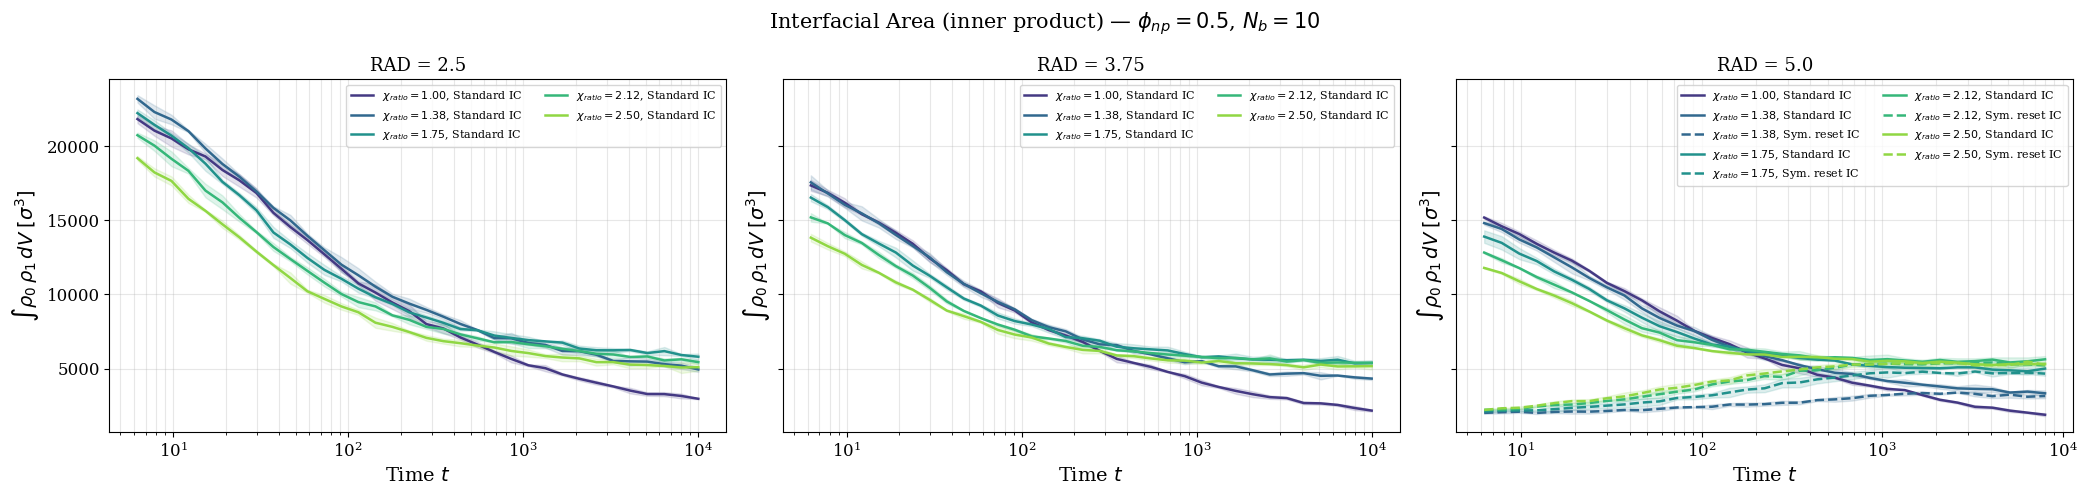

In [16]:
# Interfacial Area — Inner Product Method (plot)
# Figure per (phi_np, Nb); columns = radii; all 5 POTs as curves.
# Solid = standard IC; dashed = sym_reset IC. Shaded = ±1 std over replicas.

init_styles_ip = {
    'standard':  ('-',  'Standard IC'),
    'sym_reset': ('--', 'Sym. reset IC'),
}

pot_list_ip      = sorted(iface_ip_df['POT'].unique(), key=float)
pot_colors_ip    = sns.color_palette('viridis', len(pot_list_ip))
pot_color_map_ip = dict(zip(pot_list_ip, pot_colors_ip))

rads_ip = sorted(iface_ip_df['rad'].unique(), key=float)

for (phi_np, nb), sub_df in iface_ip_df.groupby(['phi_np', 'Nb']):
    fig, axes = plt.subplots(1, len(rads_ip),
                             figsize=(7 * len(rads_ip), 5),
                             sharey=True, squeeze=False)

    for col, rad in enumerate(rads_ip):
        ax     = axes[0][col]
        rad_df = sub_df[sub_df['rad'] == rad]

        for pot in pot_list_ip:
            chi   = float(pot) / 10.0
            color = pot_color_map_ip[pot]

            for init, (ls, init_lbl) in init_styles_ip.items():
                g = rad_df[(rad_df['POT'] == pot) & (rad_df['init'] == init)]
                if g.empty:
                    continue
                stats = g.groupby('time')['A_int_ip'].agg(['mean', 'std']).reset_index()
                ax.plot(stats['time'], stats['mean'],
                        color=color, lw=1.8, ls=ls,
                        label=rf'$\chi_{{ratio}}={chi:.2f}$, {init_lbl}')
                ax.fill_between(stats['time'],
                                stats['mean'] - stats['std'],
                                stats['mean'] + stats['std'],
                                color=color, alpha=0.15)

        ax.set_xscale('log')
        ax.set_xlabel(r'Time $t$', fontsize=14)
        ax.set_ylabel(r'$\int \rho_0\,\rho_1\,dV\;[\sigma^3]$', fontsize=14)
        ax.set_title(f'RAD = {rad}', fontsize=13)
        ax.legend(fontsize=8, frameon=True, ncol=2)
        ax.tick_params(labelsize=12)
        ax.grid(alpha=0.3, which='both')

    fig.suptitle(
        rf'Interfacial Area (inner product) — $\phi_{{np}}={phi_np}$, $N_b={nb}$',
        fontsize=15
    )
    fig.tight_layout()
    plt.show()


In [ ]:
# Cell 6: Load Symmetric Reset Data


# ── 1. Pattern and cache-aware loader ────────────────────────────────────────
sym_reset_pattern = re.compile(
    r'^sym_reset_PS_in_NP_frac_([\d.]+)_rad_([\d.]+)_POT_(10\.0|13\.75|17\.5|21\.25|25\.0)'
    r'_Nb_(\d+)_rep_(\d+)_densities\.bin$'
)

def process_file_symreset(file_path):
    filename = os.path.basename(file_path)
    m = sym_reset_pattern.match(filename)
    if not m:
        return None
    phi_np_v, rad_v, POT_v, Nb_v, rep_v = (
        m.group(1), m.group(2), m.group(3), m.group(4), m.group(5))
    cp = _cache_path('sk', phi_np_v, rad_v, POT_v, Nb_v, rep_v, 'sym_reset')
    if not FORCE_RECOMPUTE and cp.exists():
        _cached = _load_pkl(cp)
        if 'step' in _cached.columns:
            return _cached
    print(f'Processing sym_reset: {filename}')
    df = calculate_sk_from_binary(file_path, type_indices=[0, 1], k_max=2.0,
                                   max_steps=max_steps, freq=freq)
    if df.empty:
        return None
    df['phi_np'] = phi_np_v
    df['rad']    = rad_v
    df['POT']    = POT_v
    df['Nb']     = Nb_v
    df['rep']    = rep_v
    df['init']   = 'sym_reset'
    _save_pkl(df, cp)
    return df

sym_files = [f for f in files if sym_reset_pattern.match(os.path.basename(f))]
print(f'Found {len(sym_files)} sym_reset files')

if len(sym_files) == 0:
    raise RuntimeError('No sym_reset files found — check file_directory and naming convention.')

n_sym_w = choose_n_workers(len(sym_files)) if len(sym_files) >= 4 else min(len(sym_files), 2)
with Pool(processes=n_sym_w) as pool:
    sym_results = pool.map(process_file_symreset, sym_files)

sym_results = [r for r in sym_results if r is not None]
if not sym_results:
    raise RuntimeError('All sym_reset files failed to load.')

sym_data = pd.concat(sym_results, ignore_index=True)
print(f'sym_reset: {len(sym_results)} files, {len(sym_data)} rows')
print(f'  frames: {sorted(sym_data["frame"].unique())}')
print(f'  last step: {sym_data["step"].max()}')
print(f'  POT: {sorted(sym_data["POT"].unique())}')


In [ ]:
# Cell 8: IC Comparison — standard vs sym_reset

# ── Combine standard and sym_reset ────────────────────────────────────────
combined = pd.concat([data, sym_data], ignore_index=True)

# ── Comparison targets: two intermediate + final timestep ─────────────────
# step-based (not frame-based) so both 33- and 34-frame runs are compared
# at the same simulation time.
steps_cmp_targets = [steps[13], steps[23], max_steps]
target_colors     = sns.color_palette('plasma', len(steps_cmp_targets))
target_color_map  = dict(zip(steps_cmp_targets, target_colors))

init_styles_cmp = {
    'standard':  ('-',  'Standard IC'),
    'sym_reset': ('--', 'Sym. reset IC'),
}

poly_labels_c     = {0: 'Wetting', 1: 'Non-wetting'}
unique_types_comb = sorted(combined['type'].unique())

for nb_val in sorted(combined['Nb'].unique()):
    for pot_val in sorted(combined['POT'].unique(), key=float):
        if float(pot_val) <= 10.0:
            continue  # only plot chi_ratio > 1.0
        for type_val in unique_types_comb:
            sub_all = combined[
                (combined['Nb']   == nb_val) &
                (combined['POT']  == pot_val) &
                (combined['type'] == type_val)
            ]
            if sub_all.empty:
                continue

            plt.figure(figsize=(10, 7))
            for init_type, (ls, lbl_init) in init_styles_cmp.items():
                fd_init = sub_all[sub_all['init'] == init_type]
                if fd_init.empty:
                    continue
                avail_steps = np.array(fd_init['step'].unique(), dtype=float)
                for step_target in steps_cmp_targets:
                    closest = int(avail_steps[
                        np.argmin(np.abs(avail_steps - float(step_target)))])
                    fd = fd_init[fd_init['step'] == closest]
                    if fd.empty:
                        continue
                    time_val = closest * 0.005
                    k_c, sk_mean, sk_std, _ = bin_sk(
                        fd['k'].values, fd['structure_factor'].values, L_BOX, k_max=2.0
                    )
                    plt.plot(k_c, sk_mean,
                             linestyle=ls, color=target_color_map[step_target],
                             linewidth=2, label=rf'$t={time_val:.0f}$, {lbl_init}')

            pot_ratio = float(pot_val) / 10.0
            plt.title(
                rf'$N_b={nb_val}$, $\phi_{{np}}=0.5$, $\chi_{{ratio}}={pot_ratio:.3f}$, '
                rf'Polymer type = {poly_labels_c.get(int(type_val), type_val)} — $S(q)$ Comparison',
                fontsize=13
            )
            plt.xlabel(r'$|q|$', fontsize=22)
            plt.ylabel(r'$S(q)$', fontsize=22)
            plt.xlim(0, 2)
            plt.legend(fontsize=9, frameon=True, ncol=2)
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()
